# Résultats d'un sous-jeu : le protocole d'évaluation complet

> **Notebook généré.** `notebooks/resultats/_modele.ipynb` est le seul notebook de résultats écrit à la main. `scripts/generer_notebooks_resultats.py` l'exécute une fois par sous-jeu (variable d'environnement `SOUS_JEU`) et écrit `FD001.ipynb` à `FD004.ipynb`, sorties comprises. **On ne modifie jamais `FD00X.ipynb` à la main** : on modifie `_modele.ipynb`, puis on relance le script (`docs/plan_refonte_notebooks.md`, principe 2). Le sous-jeu affiché est écrit en gros sous la cellule des imports.

**Question du jury** : « Montrez-moi comment vous avez testé XGBoost ou le LSTM sur ce sous-jeu, et prouvez-moi ce résultat. »

**Ce que fait ce notebook** : il déroule le protocole d'évaluation ([`docs/protocole_evaluation.md`](../../docs/protocole_evaluation.md), règle 11 d'`AGENTS.md`) sur un sous-jeu, avec les modèles de la démo Streamlit, puis recalcule un moteur depuis les données brutes. Le calcul vit dans `src/`, une seule fois pour les 4 sous-jeux : `src/evaluation_sous_jeu.py` pour les chiffres, `src/figures_resultats.py` pour les figures. Le notebook les appelle et dit comment lire chaque résultat.

| Section | Question | Protocole |
|---|---|---|
| 1. Données du sous-jeu | Que faut-il savoir de ce sous-jeu avant de lire ses résultats ? | §1 |
| 2. Les modèles | Quels modèles, avec quels réglages, chargés ou réentraînés ? | — |
| 3. Validation croisée | Les modèles prédisent-ils bien des moteurs qu'ils n'ont jamais vus ? | §1, §3, §5.1 |
| 4. Test officiel | Quel est le chiffre officiel, et vaut-il mieux que des modèles volontairement simples ? | §2, §3 |
| 5. Classification | Les modèles déclenchent-ils l'alerte maintenance à temps ? | §4 |
| 6. Comparaison des modèles | Les écarts entre modèles sont-ils réels, moteur par moteur ? | §8 |
| 7. Vérifier un moteur | La démo affiche-t-elle bien ce que le code recalcule depuis les données brutes ? | — |

**D'où viennent les explications** : des notebooks 05 (sections A, G, H et J), 04a, 04b, 04g, 03b (F.7) et 01b (F.2) de la v1 (tag `v1-avant-reorganisation`), déplacées ici. Leur texte citait des chiffres d'anciens modèles ; ici, **chaque chiffre est calculé par le code** et affiché sous la cellule qui le produit, et les paragraphes « Ce qu'on lit » sont construits à partir de ces chiffres.

**Règles fixées avant tout résultat** (notebook 05, A.1) :
1. **Le test officiel ne sert jamais à choisir** (ni features, ni modèle, ni réglage, ni seuil d'alerte) : sinon son score deviendrait optimiste. Ici, il sert seulement à mesurer.
2. **Les mêmes plis de validation croisée pour tous les modèles** (`GroupKFold` par moteur, graine 42) : un écart entre deux modèles ne peut donc pas venir du découpage. Exception, dite en section 3 : les réseaux, validés par le notebook 04h sur d'autres découpages.
3. **Le score NASA garde ses constantes officielles 13 / 10** : c'est la note, on n'y touche pas.

Un résultat non significatif ou mixte est écrit comme tel.

## Paramètres

- **`SOUS_JEU`** : `"FD001"` à `"FD004"`. Le script de génération le donne par la variable d'environnement du même nom ; ouvert à la main, le notebook prend la valeur écrite ci-dessous.
- **`MOTEUR`** : le moteur test recalculé en section 7 (42 par défaut, le même pour les 4 sous-jeux : il n'a pas été choisi en regardant les prédictions).
- **`ENTRAINER`** (plan, section 6.2) :
  - `False` (par défaut) : les modèles sauvegardés sont chargés (`models/`) et leurs réglages affichés. « Prouve-moi ce moteur » prend quelques secondes.
  - `True` : la référence naïve et les trois modèles à arbres sont **réentraînés** en mémoire depuis `train_FD00X.txt` (même recette que le modèle final de `scripts/generer_predictions_arbres.py`), puis le notebook vérifie qu'ils redonnent les prédictions de la démo **sur tous les moteurs test** (section 2.1) et sur chaque cycle du moteur de la section 7. « Prouve-moi que ce modèle vient bien de ce code » prend quelques minutes.
  - Les réseaux (LSTM, CNN 1D) ne sont **jamais réentraînés ici** : leurs poids viennent du calcul de nuit du notebook 04h (`models/04h/`, plusieurs heures de calcul). Leur preuve est l'égalité des prédictions recalculées depuis les données brutes en section 7.

In [1]:
# --- Paramètres (cellule marquée « parameters ») ---
# Valeurs par défaut écrites ici, remplacées par les variables d'environnement du même nom quand elles existent :
# c'est ainsi que scripts/generer_notebooks_resultats.py produit les 4 notebooks (jupyter nbconvert --execute).
import os

SOUS_JEU = "FD001"  # sous-jeu évalué (écrit par scripts/generer_notebooks_resultats.py)
MOTEUR = 42  # moteur test recalculé en section 7
ENTRAINER = False  # False : modèles chargés depuis models/ ; True : arbres réentraînés puis vérifiés (plan 6.2)

# valeurs données par le script de génération (variables d'environnement), si elles existent
if os.environ.get("SOUS_JEU") is not None:
    SOUS_JEU = os.environ["SOUS_JEU"]
if os.environ.get("MOTEUR") is not None:
    MOTEUR = int(os.environ["MOTEUR"])
if os.environ.get("ENTRAINER") is not None:
    ENTRAINER = os.environ["ENTRAINER"] == "1"  # "1" : réentraîner ; toute autre valeur : charger

print(f"SOUS_JEU = {SOUS_JEU!r}, MOTEUR = {MOTEUR}, ENTRAINER = {ENTRAINER}")

SOUS_JEU = 'FD001', MOTEUR = 42, ENTRAINER = False


In [2]:
# --- Imports et chemin du dépôt ---
import sys
import time

DEBUT_NOTEBOOK = time.perf_counter()  # pour afficher la durée totale à la fin

# le notebook s'exécute depuis notebooks/resultats/ : la racine du dépôt est deux dossiers plus haut
RACINE_DEPOT = os.path.abspath(os.path.join(os.getcwd(), "..", ".."))
if not os.path.isdir(os.path.join(RACINE_DEPOT, "src")):
    raise RuntimeError(f"Dossier src/ introuvable depuis {os.getcwd()} : ouvrir ce notebook depuis notebooks/resultats/.")
if RACINE_DEPOT not in sys.path:
    sys.path.insert(0, RACINE_DEPOT)  # pour importer src/

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

# ORDRE VOULU : src.evaluation_sous_jeu importe src.inference, qui charge xgboost AVANT PyTorch
# (sinon les deux bibliothèques peuvent se bloquer mutuellement, voir src/deep_learning.py)
from src import evaluation_sous_jeu as es  # le protocole d'un sous-jeu (sections 1 à 7)
from src import figures_resultats as fr  # une fonction par figure, titrée par sa question
from src import inference as inf  # les modèles de la démo, prédiction en direct
from src.evaluation import rmse  # erreur quadratique moyenne (racine), la métrique de référence

%matplotlib inline
pd.set_option("display.width", 220)  # tableaux larges sans retour à la ligne
pd.set_option("display.max_columns", 40)
pd.set_option("display.max_colwidth", 140)

es.verifier_nom_sous_jeu(SOUS_JEU)  # FD001 à FD004, sinon erreur explicite
display(Markdown(f"# Sous-jeu {SOUS_JEU}\n\nMoteur vérifié en section 7 : n° {MOTEUR}. "
                 f"`ENTRAINER = {ENTRAINER}`."))

# Sous-jeu FD001

Moteur vérifié en section 7 : n° 42. `ENTRAINER = False`.

In [3]:
# --- Versions des bibliothèques et machine (protocole §1.6 : un chiffre se reproduit avec son environnement) ---
import importlib.metadata
import platform

# importlib.metadata lit la version installée sans importer la bibliothèque (pas d'effet sur l'ordre xgboost / torch)
lignes = []
lignes.append(("python", platform.python_version()))
lignes.append(("machine", f"{platform.system()} {platform.machine()}"))
for paquet in ["numpy", "pandas", "scikit-learn", "xgboost", "lightgbm", "torch"]:
    lignes.append((paquet, importlib.metadata.version(paquet)))
display(pd.DataFrame(lignes, columns=["composant", "version"]).set_index("composant"))
print("requirements.txt ne fixe pas ces versions : un écart de dernier chiffre (ex. XGBoost FD001 12,78 ici, "
      "12,73 publié) peut venir de l'environnement ; voir la section 6.2.")

,version
composant,
python,3.13.9
machine,Darwin arm64
numpy,2.5.3
pandas,3.0.6
scikit-learn,1.9.1
xgboost,3.4.1
lightgbm,4.7.0
torch,2.15.0


requirements.txt ne fixe pas ces versions : un écart de dernier chiffre (ex. XGBoost FD001 12,78 ici, 12,73 publié) peut venir de l'environnement ; voir la section 6.2.


## 1. Données du sous-jeu

**Question** : que faut-il savoir de ce sous-jeu avant de lire ses résultats ?

**Ce qu'on fait** : `evaluer_sous_jeu` prépare le sous-jeu exactement comme le script des arbres (`preparer_sous_jeu` : capteurs constants retirés, mise à l'échelle min-max apprise sur le train, par régime de vol sur FD002 et FD004, lissage sur 5 cycles, RUL plafonnée à 125, écart à l'état initial sur 20 cycles), calcule les 5 plis de validation croisée **une seule fois**, relit les résultats des modèles et entraîne les 5 baselines (quelques secondes). Tout le reste du notebook lit son résultat, `evaluation`. Le pourquoi de chaque étape de préparation est dans `notebooks/01_donnees.ipynb`.

**Comment lire** : nombre de régimes de vol et mode(s) de panne (description de la NASA, `data/readme.txt`), moteurs d'entraînement et de test, capteurs gardés et retirés, et la part des moteurs test dont la vraie RUL dépasse 125 (expliquée en 1.1).

In [4]:
# --- Le protocole complet du sous-jeu, calculé une fois (src/evaluation_sous_jeu.py) ---
debut = time.perf_counter()
evaluation = es.evaluer_sous_jeu(SOUS_JEU)
print(f"evaluer_sous_jeu({SOUS_JEU!r}) : {time.perf_counter() - debut:.1f} s")

# --- Description du sous-jeu : une ligne par caractéristique ---
donnees = evaluation["donnees"]
lignes = []
lignes.append(("régimes de vol", donnees["nb_regimes"]))
lignes.append(("mode(s) de panne", ", ".join(donnees["modes_de_panne"])))
lignes.append(("normalisation des capteurs", donnees["normalisation"]))
lignes.append(("moteurs d'entraînement", donnees["nb_moteurs_train"]))
lignes.append(("lignes d'entraînement (une par cycle)", donnees["nb_lignes_train"]))
lignes.append(("moteurs de test (une prédiction par moteur)", donnees["nb_moteurs_test"]))
lignes.append(("capteurs gardés", f"{len(donnees['capteurs_gardes'])} : {', '.join(donnees['capteurs_gardes'])}"))
lignes.append(("capteurs retirés (constants)", f"{len(donnees['capteurs_retires'])} : {', '.join(donnees['capteurs_retires'])}"))
lignes.append(("variables des modèles à arbres", donnees["nb_features_arbres"]))
lignes.append(("moteurs test de vraie RUL > 125", donnees["nb_rul_vraie_sup_plafond"]))
lignes.append(("part des moteurs test de vraie RUL > 125", f"{100 * donnees['part_rul_vraie_sup_plafond']:.1f} %"))
lignes.append(("plus grande vraie RUL du test", f"{donnees['rul_vraie_test_max']:.0f} cycles"))
lignes.append(("RMSE plancher dû au plafond (voir 1.1)", f"{donnees['plancher_rmse_rul_brute']:.2f} cycles"))
description = pd.DataFrame(lignes, columns=["caractéristique", "valeur"]).set_index("caractéristique")
display(description)

evaluer_sous_jeu('FD001') : 2.1 s


,valeur
caractéristique,
régimes de vol,1
mode(s) de panne,HPC Degradation
normalisation des capteurs,globale
moteurs d'entraînement,100
lignes d'entraînement (une par cycle),20631
moteurs de test (une prédiction par moteur),100
capteurs gardés,"15 : sensor_2, sensor_3, sensor_4, sensor_6, sensor_7, sensor_8, sensor_9, sensor_11, sensor_12, sensor_13, sensor_14, sensor_15, sensor..."
capteurs retirés (constants),"6 : sensor_1, sensor_5, sensor_10, sensor_16, sensor_18, sensor_19"
variables des modèles à arbres,31


### 1.1 Le plafond de 125 cycles et l'erreur du test

**Le constat** (notebook 01b, F.2, fait avec l'ancien XGBoost Phase 3 ; ses chiffres sont dans `evolution.ipynb`, étape 2) : en validation croisée, FD002 et FD004 n'étaient pas plus difficiles que FD001 ; sur le test, l'écart était net. **Hypothèse** : le plafond de 125 cycles. Le modèle a appris à ne jamais prédire beaucoup plus que 125 ; un moteur test dont la vraie RUL est 190 coûte donc au moins 65 cycles d'erreur, quelle que soit la qualité du modèle.

**Le plancher** (notebook 05, H.1) : même un modèle **parfait** sur la cible plafonnée (il prédit exactement min(vraie RUL, 125)) garde une erreur contre la RUL brute, à cause des moteurs test dont la vraie RUL dépasse 125. Ce RMSE minimal est un plancher : tant que les prédictions ne dépassent pas 125, aucun modèle ne descend en dessous.

**Test de l'hypothèse, modèle par modèle** : (1) la part des moteurs test au-dessus de 125 (tableau ci-dessus) ; (2) le RMSE plancher ; (3) le RMSE séparé sur les moteurs à vraie RUL ≤ 125 et > 125, et le biais sur ces derniers (négatif = sous-estimation).

In [5]:
# --- Le plafond explique-t-il l'erreur du test ? (cellule du notebook 01b, F.2, appliquée aux modèles du sous-jeu) ---
rul_vraie = evaluation["test"]["rul_vraie"]  # RUL_FD00X.txt, non plafonnée, une valeur par moteur test
au_dessus = rul_vraie > es.PLAFOND_RUL  # moteurs que tout modèle plafonné sous-estimera
lignes = []
for cle in evaluation["modeles"]:
    predites = evaluation["test"]["predictions"][cle]  # dernier cycle de chaque moteur test, ramené à 0 si négatif
    ecarts = predites - rul_vraie  # positif = surestimation
    ligne = {}
    ligne["modele"] = evaluation["noms"][cle]
    ligne["rmse_test"] = rmse(rul_vraie, predites)
    ligne["rmse_rul_vraie_inf_125"] = rmse(rul_vraie[~au_dessus], predites[~au_dessus])
    if au_dessus.sum() > 0:
        ligne["rmse_rul_vraie_sup_125"] = rmse(rul_vraie[au_dessus], predites[au_dessus])
        ligne["biais_rul_vraie_sup_125"] = float(np.mean(ecarts[au_dessus]))  # négatif = sous-estimation
    else:
        ligne["rmse_rul_vraie_sup_125"] = np.nan  # aucun moteur test au-dessus du plafond
        ligne["biais_rul_vraie_sup_125"] = np.nan
    ligne["prediction_max"] = float(predites.max())  # le modèle prédit-il au-delà de 125 ?
    lignes.append(ligne)
tableau_plafond = pd.DataFrame(lignes).set_index("modele")
print(f"{int(au_dessus.sum())} moteurs test sur {len(rul_vraie)} ont une vraie RUL > {es.PLAFOND_RUL} ; "
      f"RMSE plancher dû au seul plafond : {donnees['plancher_rmse_rul_brute']:.2f} cycles.")
display(tableau_plafond.round(2))

11 moteurs test sur 100 ont une vraie RUL > 125 ; RMSE plancher dû au seul plafond : 3.74 cycles.


,rmse_test,rmse_rul_vraie_inf_125,rmse_rul_vraie_sup_125,biais_rul_vraie_sup_125,prediction_max
modele,,,,,
Référence naïve (moyenne),43.07,42.38,48.23,-47.90,86.83
Random Forest,13.14,11.28,23.23,-22.23,124.38
XGBoost,12.78,10.92,22.79,-21.77,126.98
LightGBM,12.76,10.85,22.96,-21.86,126.80
LSTM,11.16,10.09,17.54,-16.35,126.16
CNN 1D,11.68,9.85,21.34,-20.21,126.84


## 2. Les modèles

**Question** : quels modèles sont évalués, avec quels réglages ?

**Les 6 modèles de la démo** (`MODELES_CONNUS`, `src/contrat_predictions.py`) : 5 qui apprennent et 1 baseline.

| Modèle | Famille | Réglages | Origine |
|---|---|---|---|
| Référence naïve | baseline | prédit toujours la RUL moyenne du train (= la baseline « Moyenne » de la section 4) | — |
| Random Forest, XGBoost, LightGBM | arbres | réglages finaux `CONFIG_*_FINAL` (`src/config_modele.py`) : recherche Optuna sur le jeu de variables retenu (capteurs lissés, `time_cycles` et écart de chaque capteur à sa moyenne des 20 premiers cycles : 31 variables sur FD001) | notebooks 04f (XGBoost) et 04g (LightGBM, Random Forest) |
| LSTM | réseau récurrent | réglages Optuna s'ils ont passé la règle de confirmation (FD001 à FD003), sinon ceux, fixés à l'avance, du 03b (FD004) ; la prédiction est la moyenne de 5 LSTM (graines 42 à 46) | notebook 04h, les 4 sous-jeux |
| CNN 1D | réseau convolutif | un seul réseau (graine 42) ; réglages Optuna s'ils ont passé la règle de confirmation (FD001 et FD003), sinon ceux, fixés à l'avance, du 03b (FD002 et FD004) | notebook 04h, les 4 sous-jeux |

**Uniquement les nouveaux modèles** (décision du 2026-11-07) : aucun modèle ancien (réglages de base, réseaux du 03b) n'est évalué ici ; leur parcours est dans `evolution.ipynb`. **Réseaux sur les 4 sous-jeux** : l'optimisation des réseaux (notebook 04h) a d'abord été faite sur FD001 et FD002 (nuit du 2026-11-07), puis sur FD003 et FD004 (nuit du 2026-11-07 au 08), avec les mêmes étapes et la même règle de confirmation. Chaque sous-jeu compare donc 6 modèles (la référence naïve, les 3 arbres et les 2 réseaux).

**Choisis sur la validation, mesurés au test** : pour chaque réseau, garder les réglages d'Optuna ou ceux du 03b, puis garder 5 LSTM ou 5 LSTM + 5 CNN, sont deux choix faits par des règles écrites avant le calcul, sur les 3 découpages neufs du 04h ; le test n'y entre pas (règle 1 ci-dessus). Un réseau retenu peut donc faire moins bien qu'un arbre au test : on le garde quand même, et on l'écrit (section 4, « Ce qu'on lit »). L'écarter après avoir vu le test reviendrait à choisir sur le test. La cellule ci-dessous relit, pour ce sous-jeu, le verdict de chaque règle dans les fichiers du 04h.

**Choisis sur FD001, appliqués tels quels** : le jeu de variables et les réglages des arbres ont été choisis sur FD001 (`02_choix_du_modele.ipynb`), puis appliqués sans changement aux autres sous-jeux.

**Comment lire** : une ligne par modèle disponible, avec ses réglages tels qu'ils sont enregistrés dans les métadonnées de son fichier de prédictions (c'est donc ce qui a réellement servi) ; puis les modèles absents et la raison.

In [6]:
# --- Modèles disponibles et leurs réglages (métadonnées des fichiers de prédictions de la démo) ---
configurations = evaluation["configurations"]
display(configurations[["modele", "famille", "description", "reglages", "date"]].set_index("modele"))

# --- Modèles absents de ce sous-jeu, et pourquoi ---
if len(evaluation["absents"]) == 0:
    print("Aucun modèle absent : les 6 modèles de la démo sont évalués.")
for cle in evaluation["absents"]:
    print(f"{es.nom_affiche(cle)} absent : {evaluation['absents'][cle]}.")

# --- Réseaux : d'où viennent leurs réglages, et pourquoi 5 LSTM ? (relu dans docs/resultats/04h/, jamais recopié) ---
import json  # lecture des fichiers de résultats du notebook 04h

# seuil de gain de la règle de l'ensemble : le même que SEUIL_GAIN_RMSE de scripts/optimiser_reseaux.py,
# écrit avant les résultats (commentaire au-dessus de ENSEMBLES_RETENUS, src/optimisation_reseaux.py)
SEUIL_GAIN_ENSEMBLE = 0.3  # cycles

phrases_reseaux = []  # une phrase par décision, construite à partir des chiffres des fichiers
if len(evaluation["validation"]["reseaux"]) > 0:
    prefixe = es.prefixe_fichiers_04h(SOUS_JEU)  # "04h_" pour FD001, "04h_fd00X_" sinon

    # (a) chaque réseau : le meilleur essai Optuna a-t-il passé la règle de confirmation contre le 03b ?
    for reseau in inf.MODELES_RESEAUX:
        chemin = os.path.join(es.DOSSIER_RESULTATS_04H, prefixe + "confirmation_" + reseau + ".json")
        with open(chemin, encoding="utf-8") as fichier:
            confirmation = json.load(fichier)
        comparaison = confirmation["comparaison"]
        chiffres = (f"gain moyen {comparaison['gain_moyen']:.3f} cycle sur les 3 découpages neufs, meilleur sur "
                    f"{comparaison['nb_decoupages_gagnes']} sur 3, p Wilcoxon = {comparaison['p_wilcoxon']:.2g}")
        if comparaison["retenu"]:
            verdict = f"réglages Optuna (essai n° {confirmation['essai_optuna']}) confirmés"
        else:
            verdict = (f"candidat Optuna (essai n° {confirmation['essai_optuna']}) **non confirmé** : réglages fixés "
                       "à l'avance du 03b gardés (réseau réentraîné par le 04h, `models/04h/`)")
        phrases_reseaux.append(f"- {es.nom_affiche(reseau)} : {verdict} ({chiffres}).")

    # (b) l'ensemble : 5 LSTM contre un seul, puis 5 LSTM + 5 CNN contre 5 LSTM (règle : gain >= 0,3 cycle)
    chemin = os.path.join(es.DOSSIER_RESULTATS_04H, prefixe + "ensemble.json")
    with open(chemin, encoding="utf-8") as fichier:
        ensembles = json.load(fichier)["ensembles"]
    rmse_5_lstm = float(np.mean(ensembles["lstm_5_graines"]["rmse_cv_par_decoupage"]))  # moyenne des 3 découpages
    contre_un_lstm = ensembles["lstm_5_graines"]["comparaison"]
    choix = "1 LSTM"  # par défaut, si l'ensemble de 5 ne passait pas la règle contre un seul LSTM
    if contre_un_lstm["retenu"]:
        choix = "5 LSTM"
    phrases_reseaux.append(f"- 5 LSTM (graines 42 à 46) contre un seul : RMSE moyen {rmse_5_lstm:.3f}, gain "
                           f"{contre_un_lstm['gain_moyen']:.3f} cycle, p Wilcoxon = {contre_un_lstm['p_wilcoxon']:.2g}, "
                           f"règle passée : {contre_un_lstm['retenu']}.")
    rmse_10 = float(np.mean(ensembles["lstm_cnn_10"]["rmse_cv_par_decoupage"]))
    gain_10_sur_5 = rmse_5_lstm - rmse_10  # positif : les 10 réseaux font mieux que les 5 LSTM
    passe_contre_un = ensembles["lstm_cnn_10"]["comparaison"]["retenu"]
    if passe_contre_un and gain_10_sur_5 >= SEUIL_GAIN_ENSEMBLE:
        choix = "5 LSTM + 5 CNN"
        suite = "au moins le seuil : la version à 10 réseaux est retenue"
    else:
        suite = f"sous le seuil de {SEUIL_GAIN_ENSEMBLE} cycle (ou règle non passée) : on garde le plus simple"
    phrases_reseaux.append(f"- 5 LSTM + 5 CNN : RMSE moyen {rmse_10:.3f} ; règle passée contre un seul LSTM : "
                           f"{passe_contre_un} ; {gain_10_sur_5:+.3f} cycle contre les 5 LSTM, {suite}.")

    # contrôle : le choix recalculé ici est celui que publie la démo (ENSEMBLES_RETENUS)
    publie = es.ENSEMBLES_RETENUS[SOUS_JEU]
    choix_publie = f"{len(publie['graines'])} LSTM"
    if publie["reseau"] != "lstm":
        choix_publie = "autre"  # cas non prévu par la règle : le contrôle échouera et le dira
    assert choix == choix_publie, f"choix recalculé {choix!r} différent de ENSEMBLES_RETENUS ({publie})"
    phrases_reseaux.append(f"- Modèle « LSTM » publié pour {SOUS_JEU} : **{choix}**, le même que `ENSEMBLES_RETENUS`. "
                           "Tous ces choix sont faits sur la validation ; le test ne sert qu'à mesurer (section 4).")
    display(Markdown(f"**Les réseaux de {SOUS_JEU} : verdict des règles du 04h**\n\n" + "\n".join(phrases_reseaux)))
else:
    print(f"{SOUS_JEU} : {es.RAISON_SANS_RESEAU}.")


,famille,description,reglages,date
modele,,,,
Référence naïve (moyenne),référence (baseline),"Reference naive (moyenne) (reference_naive, perte native) ; features : base",{},2026-11-07
Random Forest,arbres,"Random Forest (reglages finaux 04g) (random_forest, perte native) ; features : ecart_initial_20","{""n_estimators"": 391, ""max_depth"": 18, ""min_samples_leaf"": 3, ""max_features"": 0.5432, ""random_state"": 42, ""n_jobs"": -1}",2026-11-07
XGBoost,arbres,"XGBoost (reglages finaux 04f) (xgboost, perte native) ; features : ecart_initial_20","{""max_depth"": 4, ""learning_rate"": 0.0633, ""n_estimators"": 422, ""subsample"": 0.5789, ""colsample_bytree"": 0.8676, ""min_child_weight"": 1.32...",2026-11-07
LightGBM,arbres,"LightGBM (reglages finaux 04g) (lightgbm, perte native) ; features : ecart_initial_20","{""n_estimators"": 549, ""learning_rate"": 0.02744, ""num_leaves"": 8, ""min_child_samples"": 72, ""subsample"": 0.6534, ""subsample_freq"": 1, ""col...",2026-11-07
LSTM,sequentiel,"Validation croisee 5 plis par moteur sur 3 decoupages neufs (graines 1000 a 1002), notebook 04h. Moyenne simple de 5 LSTM (graines 42 a ...","{""taille_cachee"": 32, ""nb_couches"": 2, ""dropout"": 0.1270900300839567}",2026-11-08
CNN 1D,sequentiel,"Validation croisee 5 plis par moteur sur 3 decoupages neufs (graines 1000 a 1002), notebook 04h. CNN 1D, graine 42, reglages Optuna conf...","{""canaux"": [32, 32, 32], ""noyaux"": [9, 9, 9], ""dropout"": 0.053267563809498854}",2026-11-08


Aucun modèle absent : les 6 modèles de la démo sont évalués.


**Les réseaux de FD001 : verdict des règles du 04h**

- LSTM : réglages Optuna (essai n° 50) confirmés (gain moyen 1.487 cycle sur les 3 découpages neufs, meilleur sur 3 sur 3, p Wilcoxon = 9.4e-07).
- CNN 1D : réglages Optuna (essai n° 77) confirmés (gain moyen 1.305 cycle sur les 3 découpages neufs, meilleur sur 3 sur 3, p Wilcoxon = 1e-05).
- 5 LSTM (graines 42 à 46) contre un seul : RMSE moyen 7.375, gain 0.473 cycle, p Wilcoxon = 3e-06, règle passée : True.
- 5 LSTM + 5 CNN : RMSE moyen 7.351 ; règle passée contre un seul LSTM : True ; +0.024 cycle contre les 5 LSTM, sous le seuil de 0.3 cycle (ou règle non passée) : on garde le plus simple.
- Modèle « LSTM » publié pour FD001 : **5 LSTM**, le même que `ENSEMBLES_RETENUS`. Tous ces choix sont faits sur la validation ; le test ne sert qu'à mesurer (section 4).

### 2.1 Charger ou réentraîner (`ENTRAINER`)

**Ce qu'on fait** (notebook 05, J.2) : `charger_modeles` apprend la préparation sur `train_<SOUS_JEU>` (capteurs retirés, min / max des capteurs, régimes de vol), relit les modèles à arbres dans `models/` (ou les réentraîne en mémoire s'ils manquent ou ne correspondent plus à la préparation, sans rien écrire sur le disque) et relit les poids des réseaux (jamais réentraînés ici). C'est le même objet que celui de la démo Streamlit.

**Si `ENTRAINER = True`** : les modèles à arbres chargés sont remplacés par des modèles réentraînés ici, puis chaque moteur test est re-prédit **depuis `test_FD00X.txt`** à son dernier cycle par ces modèles réentraînés. On compare ces prédictions à celles des fichiers de la démo : elles doivent être identiques (écart ≤ 1e-4 cycle), et donc redonner le même RMSE.

**Comment lire** : un modèle indisponible (fichier absent) est signalé avec la raison, les autres fonctionnent.

In [7]:
# --- Les modèles de la démo, prêts à prédire en direct (src/inference.py) ---
debut = time.perf_counter()
# entrainer_si_absent=True : un arbre absent de models/ est entraîné en mémoire ; sauvegarder=False : rien n'est écrit
inference = inf.charger_modeles(SOUS_JEU, entrainer_si_absent=True, sauvegarder=False)
lignes = []
for cle in inference["modeles"]:
    modele = inference["modeles"][cle]
    ligne = {}
    ligne["modele"] = es.nom_affiche(cle)
    ligne["description"] = modele["description"]
    ligne["fichier"] = inf.chemin_lisible(modele["chemin"])
    ligne["date"] = modele["date"]
    lignes.append(ligne)
display(pd.DataFrame(lignes).set_index("modele"))
for message in inference["messages"]:
    print(message)  # par exemple : un arbre absent de models/, entraîné en mémoire
for cle in inference["indisponibles"]:
    if evaluation["absents"].get(cle) == es.RAISON_SANS_RESEAU:
        continue  # absent par décision (section 2), pas un fichier manquant
    print(f"{es.nom_affiche(cle)} indisponible : {inference['indisponibles'][cle]}")
print(f"Chargement : {time.perf_counter() - debut:.1f} s")

,description,fichier,date
modele,,,
Référence naïve (moyenne),"Reference naive (moyenne) (reference_naive, perte native)",models/FD001__reference_naive.joblib,2026-11-08T10:19:36
Random Forest,"Random Forest (reglages finaux 04g) (random_forest, perte native)",models/FD001__random_forest.joblib,2026-11-08T10:19:39
XGBoost,"XGBoost (reglages finaux 04f) (xgboost, perte native)",models/FD001__xgboost_phase3.joblib,2026-11-08T10:19:40
LightGBM,"LightGBM (reglages finaux 04g) (lightgbm, perte native)",models/FD001__lightgbm.joblib,2026-11-08T10:19:41
LSTM,"LSTM, moyenne de 5 réseaux (graines 42 à 46), fenêtre de 20 cycles, + écart à l'état initial (k = 30)",models/04h/FD001__lstm_g42.pt,2026-11-07T15:16:57
CNN 1D,"CNN 1D, fenêtre de 20 cycles, + écart à l'état initial (k = 30)",models/04h/FD001__cnn1d_g42.pt,2026-11-07T15:16:57


Chargement : 0.8 s


In [8]:
# --- ENTRAINER = True : arbres réentraînés ici, puis comparés aux prédictions de la démo sur TOUS les moteurs test ---
TOLERANCE_EGALITE = 1e-4  # cycles : même tolérance que tests/test_anti_triche.py

if not ENTRAINER:
    print("ENTRAINER = False : modèles chargés depuis models/, rien n'est réentraîné. "
          "Mettre ENTRAINER = True (ou lancer le script de génération avec --entrainer) pour les réentraîner et vérifier.")
else:
    debut = time.perf_counter()
    # même recette que le modèle final du script des arbres, en mémoire, sans rien écrire sur le disque
    durees = es.remplacer_arbres_par_reentraines(inference, SOUS_JEU)
    for cle in durees:
        print(f"{es.nom_affiche(cle)} réentraîné sur train_{SOUS_JEU} en {durees[cle]:.1f} s")

    # les modèles réentraînés (la référence naïve et les 3 arbres)
    arbres = []
    for cle in inf.MODELES_ARBRES:
        if cle in inference["modeles"]:
            arbres.append(cle)

    # prédiction au dernier cycle de chaque moteur test, recalculée depuis test_FD00X.txt par les modèles réentraînés
    predictions_reentrainees = {}
    for cle in arbres:
        predictions_reentrainees[cle] = []
    for moteur in evaluation["test"]["moteurs"]:
        nb_cycles = inf.mesures_moteur_test(SOUS_JEU, int(moteur))["nb_cycles"]  # dernier cycle observé
        verification_moteur = es.verifier_moteur(SOUS_JEU, int(moteur), inference=inference, modeles=arbres,
                                                 cycles=[nb_cycles])
        dernier = verification_moteur["dernier_cycle"].set_index("cle")
        for cle in arbres:
            predictions_reentrainees[cle].append(float(dernier.loc[cle, "rul_predite"]))

    # comparaison aux fichiers de la démo (lus par evaluer_sous_jeu, section 4)
    lignes = []
    for cle in arbres:
        recalculees = np.clip(np.array(predictions_reentrainees[cle]), a_min=0, a_max=None)  # même règle que le test
        demo = evaluation["test"]["predictions"][cle]
        ligne = {}
        ligne["modele"] = es.nom_affiche(cle)
        ligne["rmse_test_reentraine"] = rmse(evaluation["test"]["rul_vraie"], recalculees)
        ligne["rmse_test_demo"] = rmse(evaluation["test"]["rul_vraie"], demo)
        ligne["ecart_max_predictions"] = float(np.max(np.abs(recalculees - demo)))
        ligne["identique"] = bool(ligne["ecart_max_predictions"] <= TOLERANCE_EGALITE)
        lignes.append(ligne)
    controle_reentrainement = pd.DataFrame(lignes).set_index("modele")
    display(controle_reentrainement)
    print(f"Réentraînement et {len(evaluation['test']['moteurs'])} moteurs re-prédits : "
          f"{time.perf_counter() - debut:.1f} s")
    assert controle_reentrainement["identique"].all(), "Un modèle réentraîné ne redonne pas les prédictions de la démo."

ENTRAINER = False : modèles chargés depuis models/, rien n'est réentraîné. Mettre ENTRAINER = True (ou lancer le script de génération avec --entrainer) pour les réentraîner et vérifier.


## 3. Validation croisée

**Question** : les modèles prédisent-ils bien des moteurs qu'ils n'ont jamais vus pendant l'entraînement ?

**Ce qu'on fait** (notebook 05, A.4) : on répartit les moteurs d'entraînement en 5 groupes ; chaque groupe sert une fois de validation pendant que les 4 autres servent à apprendre (`GroupKFold`, graine 42, `calculer_plis`). **Pourquoi par moteur** : un moteur entier est soit en apprentissage, soit en validation ; sinon le modèle verrait des cycles voisins du même moteur des deux côtés et paraîtrait meilleur qu'il n'est. Les 3 arbres, la référence naïve et les 5 baselines utilisent **exactement les mêmes plis** : `evaluer_sous_jeu` vérifie, pli par pli, que les moteurs de validation sont ceux du script qui a calculé la validation des arbres avec leurs réglages finaux (`scripts/valider_arbres_finaux.py`, résultats dans `sorties/resultats/refonte/`), et que le RMSE de chaque pli se recalcule à l'identique.

**Exception : les réseaux.** Leur validation croisée vient du notebook 04h : 5 plis par moteur sur **3 découpages neufs** (graines 1000 à 1002, jamais vus par Optuna), pas les plis des arbres, et leurs prédictions hors-pli n'ont pas été enregistrées. Leur ligne donne donc la moyenne ± écart-type **entre les 3 découpages** (colonne « écart-type entre »), pas entre 5 plis. Pour que les moyennes se comparent, les arbres ont **aussi** été validés sur ces 3 mêmes découpages neufs (`scripts/valider_arbres_finaux.py --complements`, sur chaque sous-jeu qui a des réseaux) : colonne « RMSE découpages neufs », la même pour tous les modèles d'un sous-jeu qui a des réseaux. Ce sont les mêmes découpages par moteur, mais ce n'est toujours pas un test apparié (les prédictions hors-pli des réseaux n'ont pas été enregistrées, section 6).

**Cases vides des réseaux** : le notebook 04h n'a pas enregistré les mêmes choses pour les deux réseaux. Pour le LSTM (moyenne de 5 réseaux), seul le RMSE de chaque découpage est enregistré : MAE, NASA et « surestimés » restent vides. Pour le CNN 1D (un seul réseau), les métriques hors-pli de chaque découpage sont enregistrées : elles sont affichées (moyenne des 3 découpages). La colonne « note » le rappelle.

**Optimisme** : sur FD001, les réglages des arbres ont été cherchés par Optuna (04f, 04g) ; leur validation croisée sur FD001 est donc un peu optimiste (biais d'optimisme, protocole §6). Sur les autres sous-jeux, ces réglages n'ont pas été cherchés, seulement appliqués.

**Comment lire** (notebook 04a, section 4) : RMSE moyen ± écart-type entre plis, en cycles. Un écart entre deux modèles plus petit que l'écart-type entre plis n'est pas une différence établie. « NASA moyen par ligne » = pénalité moyenne par prédiction (la somme, elle, dépend du nombre de lignes) ; « surestimés > 20 » = part des lignes surestimées de plus de 20 cycles.

In [9]:
# --- Tableau de la validation croisée : RMSE moyen ± écart-type, et le protocole de chaque ligne ---
validation = evaluation["validation"]["tableau"]
lignes = []
for indice in validation.index:
    source = validation.loc[indice]
    ligne = {}
    ligne["modele"] = source["modele"]
    ligne["RMSE CV"] = es.formater_moyenne_ecart(source["rmse_cv_moyen"], source["rmse_cv_ecart_type"])
    ligne["MAE CV"] = round(float(source["mae_cv_moyen"]), 2)  # NaN pour l'ensemble de LSTM (non enregistrée par le 04h)
    ligne["NASA moyen par ligne"] = round(float(source["nasa_moyen_par_ligne"]), 2)
    ligne["surestimés > 20 (%)"] = round(float(source["surestimes_pct"]), 1)  # NaN pour l'ensemble de LSTM
    ligne["écart-type entre"] = source["ecart_type_entre"]
    if len(evaluation["validation"]["reseaux"]) > 0:
        # sous-jeu avec réseaux : la même mesure pour tous, sur les 3 découpages neufs du 04h
        if pd.isna(source["rmse_decoupages_neufs_moyen"]):
            ligne["RMSE découpages neufs"] = ""  # baselines : non calculé sur ces découpages
        else:
            ligne["RMSE découpages neufs"] = es.formater_moyenne_ecart(source["rmse_decoupages_neufs_moyen"],
                                                                       source["rmse_decoupages_neufs_ecart_type"])
    ligne["note"] = source["note"]
    lignes.append(ligne)
display(pd.DataFrame(lignes).set_index("modele"))
print("Arbres et baselines :", evaluation["validation"]["protocole_arbres"])
if len(evaluation["validation"]["reseaux"]) > 0:  # faux seulement pour un sous-jeu sans réseau
    print("Réseaux :", evaluation["validation"]["protocole_reseaux"])
    print("RMSE découpages neufs :", evaluation["validation"]["protocole_decoupages_neufs"])
for manquant in evaluation["validation"]["complements_manquants"]:
    print("Complément absent :", manquant)

,RMSE CV,MAE CV,NASA moyen par ligne,surestimés > 20 (%),écart-type entre,RMSE découpages neufs,note
modele,,,,,,,
Référence naïve (moyenne),41.69 ± 0.12,36.98,308.87,32.6,5 plis,41.69 ± 0.01,
Random Forest,9.95 ± 0.58,6.61,1.69,4.0,5 plis,9.71 ± 0.09,
XGBoost,9.12 ± 0.43,6.12,1.45,3.4,5 plis,9.00 ± 0.13,
LightGBM,9.06 ± 0.39,6.07,1.42,3.4,5 plis,8.95 ± 0.12,
LSTM,7.38 ± 0.02,NaN,NaN,NaN,3 decoupages,7.38 ± 0.02,04h : RMSE par découpage seulement (ensemble de 5 LSTM)
CNN 1D,8.30 ± 0.12,5.57,1.17,2.5,3 decoupages,8.30 ± 0.12,"04h : RMSE par pli et métriques hors-pli (MAE, NASA, surestimés, biais)"
Moyenne,41.69 ± 0.12,36.98,308.87,32.6,5 plis,,
Mediane,44.67 ± 0.87,35.80,1495.95,40.2,5 plis,,
Constante 125,56.54 ± 1.01,38.22,13684.42,51.0,5 plis,,


Arbres et baselines : GroupKFold par moteur, 5 plis, graine 42 (calculer_plis), reglages finaux (CONFIG_*_FINAL) ; mêmes plis pour les arbres et les 5 baselines
Réseaux : notebook 04h : 5 plis par moteur sur 3 découpages neufs (graines 1000 à 1002) ; plis différents de ceux des arbres, prédictions hors-pli non enregistrées
RMSE découpages neufs : 5 plis par moteur sur les 3 découpages neufs du notebook 04h (graines 1000 à 1002), les mêmes pour les arbres et les réseaux ; moyenne ± écart-type entre les 3 découpages


In [10]:
# --- Le RMSE de chacun des 3 découpages neufs : réseaux (relu dans docs/resultats/04h/) et arbres (complément) ---
reseaux = evaluation["validation"]["reseaux"]
if len(reseaux) == 0:
    print(f"{SOUS_JEU} : {es.RAISON_SANS_RESEAU}.")
else:
    lignes = []
    # les arbres sur les mêmes découpages (scripts/valider_arbres_finaux.py --complements), s'ils ont été calculés
    decoupages_arbres = evaluation["validation"]["decoupages_neufs"]
    if decoupages_arbres is not None:
        for cle in evaluation["modeles"]:
            selection = decoupages_arbres[decoupages_arbres["cle"] == cle]
            if len(selection) == 0:
                continue  # réseau : traité juste après
            ligne = {}
            ligne["modele"] = evaluation["noms"][cle]
            for indice in selection.sort_values("graine_plis").index:
                ligne[f"découpage {int(selection.loc[indice, 'graine_plis'])}"] = round(float(selection.loc[indice, "rmse_cv_moyen"]), 3)
            ligne["moyenne"] = round(float(np.mean(selection["rmse_cv_moyen"])), 3)
            ligne["source"] = "sorties/resultats/refonte/cv_arbres_finaux_decoupages_neufs.csv"
            lignes.append(ligne)
    # les réseaux, relus dans les résultats du 04h
    for cle in reseaux:
        reseau = reseaux[cle]
        ligne = {}
        ligne["modele"] = reseau["modele"]
        for graine, valeur in zip(reseau["graines_decoupages"], reseau["rmse_par_decoupage"]):
            ligne[f"découpage {graine}"] = round(valeur, 3)
        ligne["moyenne"] = round(reseau["rmse_cv_moyen"], 3)
        ligne["source"] = reseau["source"]
        lignes.append(ligne)
    display(pd.DataFrame(lignes).set_index("modele"))

,découpage 1000,découpage 1001,découpage 1002,moyenne,source
modele,,,,,
Référence naïve (moyenne),41.695,41.700,41.677,41.691,sorties/resultats/refonte/cv_arbres_finaux_decoupages_neufs.csv
Random Forest,9.673,9.832,9.634,9.713,sorties/resultats/refonte/cv_arbres_finaux_decoupages_neufs.csv
XGBoost,8.854,9.175,8.961,8.997,sorties/resultats/refonte/cv_arbres_finaux_decoupages_neufs.csv
LightGBM,8.838,9.119,8.881,8.946,sorties/resultats/refonte/cv_arbres_finaux_decoupages_neufs.csv
LSTM,7.396,7.386,7.343,7.375,docs/resultats/04h/04h_ensemble.json
CNN 1D,8.131,8.408,8.347,8.295,docs/resultats/04h/04h_confirmation_cnn1d.json (cv_candidat)


### 3.1 Toutes les métriques de régression, et le diagnostic de sur-apprentissage des baselines

**Les métriques** (notebook 05, G.3), pour un écart e = prédiction − vérité (en cycles) :

| Métrique | Sens | Exemple |
|---|---|---|
| MAE | moyenne des \|e\| : l'erreur typique | erreurs de 5 et 15 cycles → MAE = 10 |
| RMSE | racine de la moyenne des e² : pénalise davantage les grosses erreurs | 5 et 15 → RMSE = 11,2 |
| R² | part de la variation de la RUL expliquée : 1 = parfait, 0 = pas mieux que la moyenne, négatif = pire | |
| erreur abs. médiane | la moitié des erreurs sont plus petites : insensible à quelques erreurs énormes | |
| erreur max | la pire erreur | |
| biais | moyenne des e : positif = le modèle surestime en moyenne (dangereux), négatif = il sous-estime (prudent) | |
| NASA somme / moyen | score asymétrique 13/10 : somme des pénalités, et pénalité moyenne par prédiction | |
| surestimés > 20 | nombre et % de prédictions qui surestiment de plus de 20 cycles | |

Toutes sont calculées par un seul appel, `metriques_regression` (`src/evaluation.py`), à l'identique pour la validation et le test. **Comment lire** : moyenne ± écart-type des 5 plis (`np.std`, ddof = 0) ; seuls les modèles qui ont des prédictions hors-pli (arbres et baselines) y figurent. Les prédictions hors-pli des arbres et de Ridge ne sont pas ramenées à 0.

**Diagnostic de sur-apprentissage** (notebook 05, G.2) : pour les baselines, erreur sur les moteurs d'entraînement (moyenne des 5 plis) contre erreur sur les moteurs de validation. Un écart faible veut dire que la baseline n'apprend pas par cœur ; un niveau élevé, qu'elle est trop simple (sous-apprentissage). **Même diagnostic pour les modèles à arbres** (protocole §5.1, notebook 04a, section 4) : `scripts/valider_arbres_finaux.py --complements` réentraîne chaque arbre pli par pli et le fait prédire aussi ses moteurs d'entraînement ; on lit le RMSE train contre le RMSE validation, pli par pli (le RMSE de validation recalculé est contrôlé contre celui du tableau ci-dessus). Un grand écart veut dire que le modèle apprend en partie par cœur (variance) ; c'est attendu pour une forêt aléatoire, dont les arbres profonds reproduisent presque le train. Les réseaux n'ont pas cette mesure (section 6.2) ; leur diagnostic est dans `02_choix_du_modele.ipynb`, sur FD001.

**MAPE** : affichée « écartée » dans le tableau quand la validation contient des RUL vraies nulles (le dernier cycle de chaque moteur) : la division par 0 donne un nombre absurde (section 4.1).

In [11]:
# --- Toutes les métriques de validation, moyenne ± écart-type des 5 plis ---
METRIQUES_VALIDATION = ["rmse", "mae", "r2", "erreur_absolue_mediane", "erreur_max", "biais", "nasa_moyen",
                        "surestimes_pct", "mse", "mape"]
complet = evaluation["validation"]["complet"]
lignes = []
for indice in complet.index:
    source = complet.loc[indice]
    ligne = {}
    ligne["modele"] = source["modele"]
    for metrique in METRIQUES_VALIDATION:
        ligne[metrique] = es.formater_moyenne_ecart(source[metrique + "_moyenne"], source[metrique + "_ecart_type"])
    # MAPE : division par une RUL vraie nulle (dernier cycle de chaque moteur) -> valeur absurde, écartée (4.1)
    if source["nb_rul_vraie_nulle_moyenne"] > 0:
        ligne["mape"] = f"écartée ({source['nb_rul_vraie_nulle_moyenne']:.0f} RUL nulles par pli)"
    lignes.append(ligne)
display(pd.DataFrame(lignes).set_index("modele"))

# --- Baselines : erreur sur les moteurs d'entraînement contre erreur de validation (sur-apprentissage ?) ---
train = evaluation["validation"]["train_baselines"].set_index("cle")
complet_par_cle = complet.set_index("cle")
lignes = []
for nom in es.BASELINES:
    ligne = {}
    ligne["baseline"] = nom
    ligne["RMSE train (moyenne des plis)"] = round(float(train.loc[nom, "rmse_moyenne"]), 2)
    ligne["RMSE validation"] = round(float(complet_par_cle.loc[nom, "rmse_moyenne"]), 2)
    ligne["écart validation − train"] = round(ligne["RMSE validation"] - ligne["RMSE train (moyenne des plis)"], 2)
    ligne["R² train"] = round(float(train.loc[nom, "r2_moyenne"]), 3)
    ligne["R² validation"] = round(float(complet_par_cle.loc[nom, "r2_moyenne"]), 3)
    lignes.append(ligne)
display(pd.DataFrame(lignes).set_index("baseline"))

# --- Modèles à arbres : erreur sur les moteurs d'entraînement contre erreur de validation, pli par pli ---
train_arbres = evaluation["validation"]["train_arbres"]
if train_arbres is None:
    print("Erreur d'entraînement des arbres absente :", "; ".join(evaluation["validation"]["complements_manquants"]))
else:
    lignes = []
    for indice in train_arbres.index:
        source = train_arbres.loc[indice]
        ligne = {}
        ligne["modele"] = source["modele"]
        ligne["RMSE train (5 plis)"] = es.formater_moyenne_ecart(source["rmse_train_moyen"], source["rmse_train_ecart_type"])
        ligne["RMSE validation (5 plis)"] = es.formater_moyenne_ecart(source["rmse_val_moyen"], source["rmse_val_ecart_type"])
        ligne["écart validation − train"] = round(float(source["ecart_val_moins_train"]), 2)
        ligne["plis où validation > train"] = f"{int(source['nb_plis_val_superieure'])} / 5"
        ligne["R² train"] = round(float(source["r2_train_moyen"]), 3)
        ligne["R² validation"] = round(float(source["r2_val_moyen"]), 3)
        lignes.append(ligne)
    display(pd.DataFrame(lignes).set_index("modele"))

,rmse,mae,r2,erreur_absolue_mediane,erreur_max,biais,nasa_moyen,surestimes_pct,mse,mape
modele,,,,,,,,,,
Référence naïve (moyenne),41.69 ± 0.12,36.98 ± 0.09,-0.00 ± 0.00,38.17 ± 0.34,86.83 ± 0.34,0.05 ± 1.71,308.87 ± 20.45,32.62 ± 1.32,1738.01 ± 10.21,écartée (20 RUL nulles par pli)
Random Forest,9.95 ± 0.58,6.61 ± 0.40,0.94 ± 0.01,3.91 ± 0.27,44.97 ± 5.34,-0.31 ± 1.79,1.69 ± 0.32,4.04 ± 1.26,99.27 ± 11.90,écartée (20 RUL nulles par pli)
XGBoost,9.12 ± 0.43,6.12 ± 0.20,0.95 ± 0.00,3.73 ± 0.12,45.40 ± 5.39,-0.14 ± 1.08,1.45 ± 0.30,3.41 ± 0.96,83.43 ± 8.10,écartée (20 RUL nulles par pli)
LightGBM,9.06 ± 0.39,6.07 ± 0.21,0.95 ± 0.00,3.71 ± 0.25,44.27 ± 5.15,-0.16 ± 1.13,1.42 ± 0.27,3.35 ± 1.19,82.15 ± 7.31,écartée (20 RUL nulles par pli)
Moyenne,41.69 ± 0.12,36.98 ± 0.09,-0.00 ± 0.00,38.17 ± 0.34,86.83 ± 0.34,0.05 ± 1.71,308.87 ± 20.45,32.62 ± 1.32,1738.01 ± 10.21,écartée (20 RUL nulles par pli)
Mediane,44.67 ± 0.87,35.80 ± 0.49,-0.15 ± 0.04,22.20 ± 0.75,102.80 ± 0.75,16.02 ± 2.11,1495.95 ± 167.05,40.20 ± 1.80,1996.19 ± 78.30,écartée (20 RUL nulles par pli)
Constante 125,56.54 ± 1.01,38.22 ± 1.37,-0.84 ± 0.06,22.40 ± 3.88,125.00 ± 0.00,38.22 ± 1.37,13684.42 ± 489.37,50.96 ± 1.82,3197.68 ± 114.35,écartée (20 RUL nulles par pli)
Aleatoire uniforme,60.31 ± 0.54,50.03 ± 0.45,-1.10 ± 0.05,45.10 ± 0.66,124.97 ± 0.03,-24.24 ± 1.43,1790.55 ± 123.16,21.65 ± 0.78,3637.79 ± 65.32,écartée (20 RUL nulles par pli)
Ridge,16.95 ± 0.48,13.77 ± 0.53,0.83 ± 0.01,11.98 ± 0.72,57.58 ± 2.10,-0.38 ± 2.33,4.64 ± 0.42,13.98 ± 3.54,287.46 ± 15.83,écartée (20 RUL nulles par pli)


,RMSE train (moyenne des plis),RMSE validation,écart validation − train,R² train,R² validation
baseline,,,,,
Moyenne,41.67,41.69,0.02,0.000,-0.002
Mediane,44.63,44.67,0.04,-0.147,-0.150
Constante 125,56.51,56.54,0.03,-0.839,-0.843
Aleatoire uniforme,60.20,60.31,0.11,-1.087,-1.097
Ridge,15.70,16.95,1.25,0.858,0.834


,RMSE train (5 plis),RMSE validation (5 plis),écart validation − train,plis où validation > train,R² train,R² validation
modele,,,,,,
Référence naïve (moyenne),41.67 ± 0.03,41.69 ± 0.12,0.02,3 / 5,0.000,-0.002
Random Forest,3.08 ± 0.06,9.95 ± 0.58,6.86,5 / 5,0.995,0.943
XGBoost,5.45 ± 0.11,9.12 ± 0.43,3.67,5 / 5,0.983,0.952
LightGBM,6.56 ± 0.09,9.06 ± 0.39,2.49,5 / 5,0.975,0.953


### 3.2 L'erreur selon la distance à la panne (tranches de vraie RUL)

**Pourquoi** (notebook 05, G.4) : une erreur de 10 cycles n'a pas la même gravité à 20 cycles de la panne qu'à 100. Le protocole demande l'erreur par tranche de vraie RUL : ≤ 30 (zone d'alerte), 31 à 60, 61 à 125, et > 125 (seulement sur le test, section 4.2 : la cible d'entraînement ne dépasse pas 125). En validation, on regroupe les prédictions des 5 plis : chaque ligne du train est prédite exactement une fois, par un modèle qui ne l'a pas vue (notebook 04a, section 5).

**Comment lire** : chaque case donne « MAE / RMSE / biais » en cycles ; un biais positif dans la tranche ≤ 30 serait le cas le plus dangereux (le modèle croit le moteur plus jeune qu'il n'est). La dernière ligne donne le nombre de lignes de chaque tranche. Les réseaux n'y figurent pas (pas de prédictions hors-pli enregistrées).

In [12]:
# --- Erreur par tranche de vraie RUL, en validation : « MAE / RMSE / biais » par case ---
tranches = evaluation["tranches"]
tranches_validation = tranches[tranches["ensemble"] == "validation"]
cases = {}  # modèle -> {tranche -> texte}
effectifs = {}  # tranche -> nombre de lignes (le même pour tous les modèles)
for indice in tranches_validation.index:
    source = tranches_validation.loc[indice]
    if source["modele"] not in cases:
        cases[source["modele"]] = {}
    cases[source["modele"]][source["tranche"]] = f"{source['mae']:.2f} / {source['rmse']:.2f} / {source['biais']:+.2f}"
    effectifs[source["tranche"]] = str(int(source["n"]))
tableau_tranches_validation = pd.DataFrame.from_dict(cases, orient="index")
tableau_tranches_validation.loc["n (lignes)"] = pd.Series(effectifs)
display(tableau_tranches_validation)

,<= 30,31-60,61-125
Référence naïve (moyenne),71.83 / 72.38 / +71.83,41.33 / 42.22 / +41.33,28.65 / 31.33 / -23.88
Random Forest,2.87 / 3.82 / +1.44,6.63 / 9.22 / +3.50,7.41 / 10.97 / -1.56
XGBoost,2.95 / 3.93 / +0.97,5.80 / 7.99 / +2.22,6.87 / 10.11 / -0.91
LightGBM,3.05 / 4.06 / +0.98,5.84 / 8.04 / +1.97,6.77 / 10.00 / -0.90
Moyenne,71.83 / 72.38 / +71.83,41.33 / 42.22 / +41.33,28.65 / 31.33 / -23.88
Mediane,87.80 / 88.26 / +87.80,57.30 / 57.95 / +57.30,20.24 / 21.80 / -7.92
Constante 125,110.00 / 110.36 / +110.00,79.50 / 79.97 / +79.50,14.31 / 24.81 / +14.31
Aleatoire uniforme,50.19 / 60.54 / +47.91,34.62 / 41.23 / +17.02,53.20 / 63.52 / -48.22
Ridge,15.49 / 18.94 / -1.39,19.26 / 22.04 / +16.49,12.29 / 15.22 / -3.74
n (lignes),3100,3000,14531


### 3.3 Figures de la validation : prédit contre vrai, et résidus selon la vraie RUL

**Comment lire** (notebook 04a, section 7) : prédictions hors-pli des 5 plis regroupées (une par ligne du train), d'où la transparence des points. À gauche, la diagonale est la prédiction parfaite ; au-dessus, le modèle surestime (dangereux). À droite, résidu = prédit − vrai selon la vraie RUL ; la ligne rouge est la moyenne des résidus par paquet de 10 cycles. Seuls les modèles qui ont des prédictions hors-pli sont tracés (pas les réseaux).

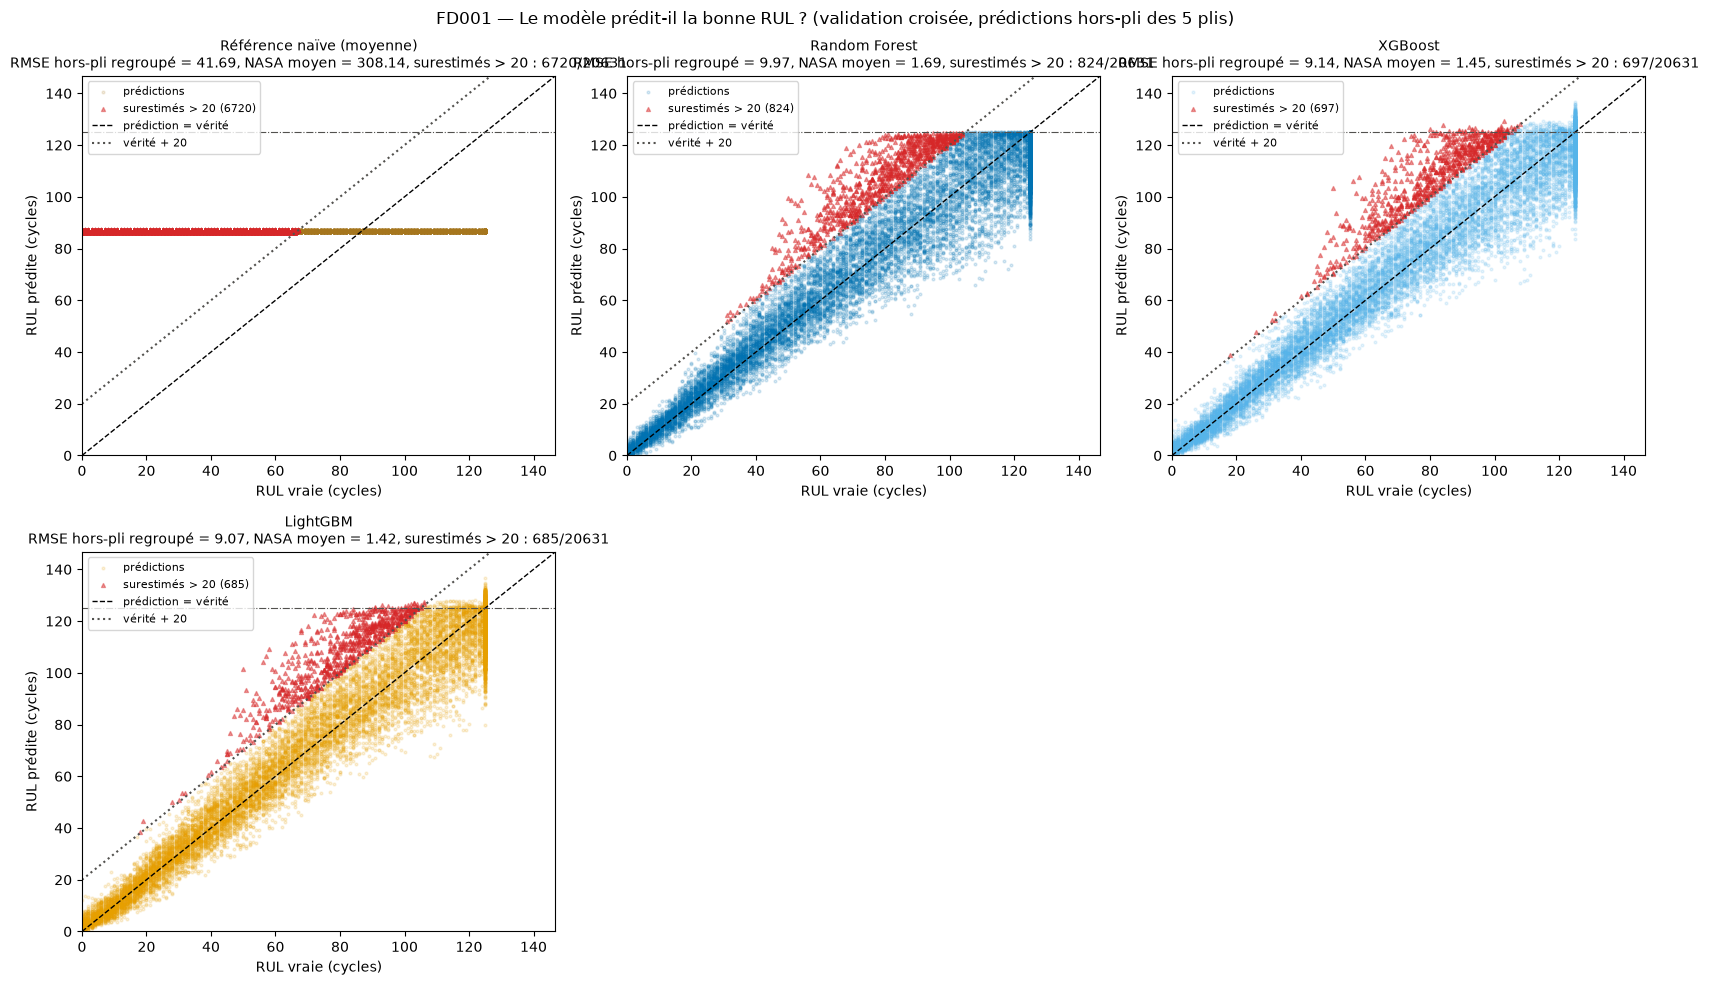

In [13]:
# --- Figure : RUL prédite contre vraie, validation (src/figures_resultats.py) ---
figure = fr.figure_predit_vs_vrai(evaluation, ensemble="validation")
plt.show()

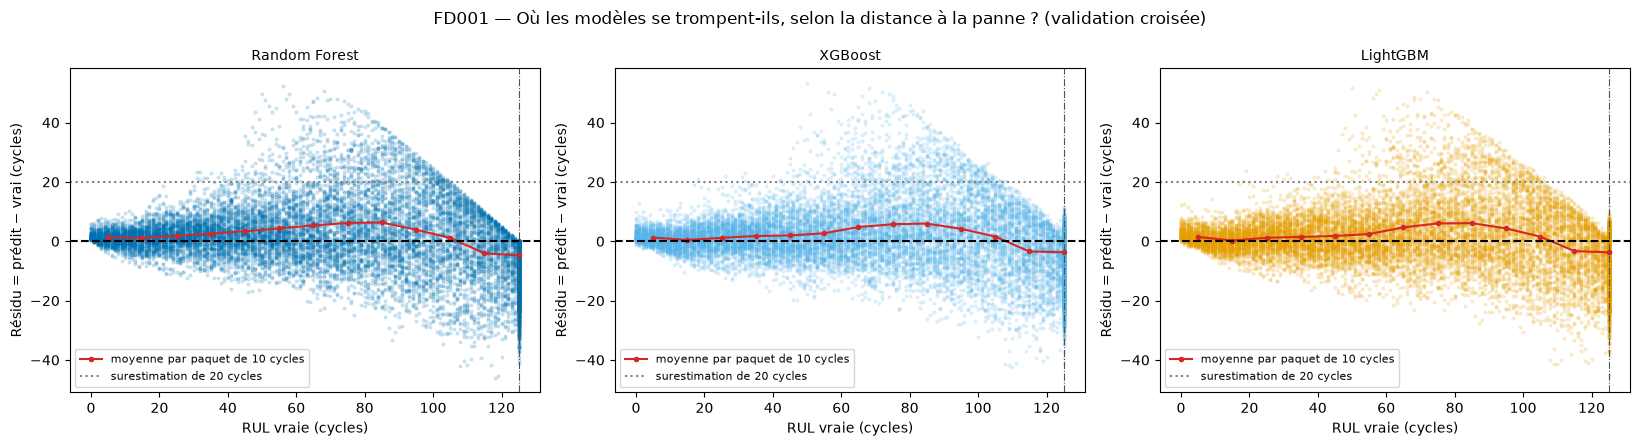

In [14]:
# --- Figure : résidus selon la vraie RUL, validation ---
figure = fr.figure_residus_selon_rul(evaluation, ensemble="validation")
plt.show()

In [15]:
# --- Ce qu'on lit dans la validation croisée (phrases construites à partir des chiffres ci-dessus) ---
tableau = evaluation["validation"]["tableau"].set_index("cle")
appris = []  # les modèles qui apprennent, disponibles sur ce sous-jeu (sans la référence naïve)
for cle in evaluation["modeles"]:
    if cle != "reference_naive":
        appris.append(cle)
meilleur = appris[0]
moins_bon = appris[0]
for cle in appris:
    if tableau.loc[cle, "rmse_cv_moyen"] < tableau.loc[meilleur, "rmse_cv_moyen"]:
        meilleur = cle
    if tableau.loc[cle, "rmse_cv_moyen"] > tableau.loc[moins_bon, "rmse_cv_moyen"]:
        moins_bon = cle
meilleure_baseline = es.BASELINES[0]
for nom in es.BASELINES:
    if tableau.loc[nom, "rmse_cv_moyen"] < tableau.loc[meilleure_baseline, "rmse_cv_moyen"]:
        meilleure_baseline = nom

phrases = []
phrases.append(f"- RMSE de validation des modèles qui apprennent : de {tableau.loc[meilleur, 'rmse_cv_moyen']:.2f} "
               f"({evaluation['noms'][meilleur]}) à {tableau.loc[moins_bon, 'rmse_cv_moyen']:.2f} "
               f"({evaluation['noms'][moins_bon]}) ; meilleure baseline : {meilleure_baseline}, "
               f"{tableau.loc[meilleure_baseline, 'rmse_cv_moyen']:.2f} ; référence naïve (moyenne) : "
               f"{tableau.loc['Moyenne', 'rmse_cv_moyen']:.2f}.")
if len(evaluation["validation"]["reseaux"]) > 0:
    # les moyennes sur les 3 découpages neufs (les mêmes pour tous), quand elles existent
    neufs = []
    for cle in appris:
        if not pd.isna(tableau.loc[cle, "rmse_decoupages_neufs_moyen"]):
            neufs.append(f"{evaluation['noms'][cle]} {tableau.loc[cle, 'rmse_decoupages_neufs_moyen']:.2f}")
    if len(neufs) == len(appris):
        phrases.append("- Sur les 3 mêmes découpages neufs du 04h (RMSE moyen) : " + ", ".join(neufs) + ". Mêmes "
                       "découpages, mais pas de test apparié arbres contre réseaux (prédictions hors-pli des réseaux "
                       "non enregistrées) : l'écart est indicatif.")
    else:
        phrases.append("- Les réseaux sont validés sur d'autres découpages que les arbres (3 découpages neufs du 04h) : "
                       "l'écart entre leurs moyennes et celles des arbres est indicatif, pas testé.")
else:
    phrases.append(f"- Pas de réseau sur {SOUS_JEU} : seuls les arbres et les baselines sont validés, tous sur les mêmes plis.")
display(Markdown("**Ce qu'on lit (validation croisée)**\n\n" + "\n".join(phrases)))

**Ce qu'on lit (validation croisée)**

- RMSE de validation des modèles qui apprennent : de 7.38 (LSTM) à 9.95 (Random Forest) ; meilleure baseline : Ridge, 16.95 ; référence naïve (moyenne) : 41.69.
- Sur les 3 mêmes découpages neufs du 04h (RMSE moyen) : Random Forest 9.71, XGBoost 9.00, LightGBM 8.95, LSTM 7.38, CNN 1D 8.30. Mêmes découpages, mais pas de test apparié arbres contre réseaux (prédictions hors-pli des réseaux non enregistrées) : l'écart est indicatif.

## 4. Test officiel

**Question** : quel est le chiffre officiel, et vaut-il mieux que des modèles volontairement simples ?

**Ce qu'on fait** (notebook 04a, section 6 ; notebook 05, G.1 et G.2) : rien n'est choisi ici. Une prédiction par moteur test, au **dernier cycle observé** (`test_FD00X.txt`), comparée à la vraie RUL de `RUL_FD00X.txt` (**non plafonnée**), puis à la RUL plafonnée à 125 (pour la littérature, 4.4). Les prédictions négatives sont ramenées à 0 (une RUL négative n'a pas de sens physique), pour tous les modèles et toutes les baselines.
- Les prédictions des modèles sont **lues dans les fichiers de la démo** (`sorties/predictions/`) : la démo et les notebooks lisent les mêmes résultats (principe 4 du plan). `evaluer_sous_jeu` vérifie que les métriques publiées dans ces fichiers se recalculent à l'identique (`verifier_coherence`, cellule suivante).
- Les **5 baselines** (protocole §2) sont réentraînées sur tous les moteurs d'entraînement :

| Baseline | Ce qu'elle prédit |
|---|---|
| Moyenne | toujours la RUL moyenne du train (c'est exactement la « référence naïve » de la démo) |
| Médiane | toujours la RUL médiane du train |
| Constante 125 | toujours 125 : « le moteur est neuf » |
| Aléatoire | un nombre tiré au hasard entre 0 et 125 (graine fixée) |
| Ridge | une **régression linéaire** sur les variables des arbres (petite pénalité, `alpha = 1`, non réglée) ; variables centrées-réduites, réglage appris sur le train |

**Pourquoi** : un RMSE de 12 cycles n'a de sens que comparé à ce que ferait un modèle sans intelligence.

**Rappel** (protocole §1.5) : validation = toutes les lignes, cible plafonnée ; test = une prédiction par moteur, vérité non plafonnée. Les sommes de score NASA ne sont pas comparables entre les deux ; on compare les moyennes par prédiction.

In [16]:
# --- Contrôle : les métriques publiées dans les fichiers de la démo se recalculent à l'identique ---
controle = evaluation["test"]["controle_contrat"]
print(f"{len(controle)} métriques publiées contrôlées dans {controle['cle'].nunique()} fichiers de prédictions : "
      f"{int(controle['coherent'].sum())} identiques au recalcul, écart maximal {controle['ecart'].abs().max():.1e}.")
assert controle["coherent"].all()

# --- Le tableau du test officiel : les métriques gardées (section 4.1), contre la RUL brute ---
brute = evaluation["regression"]["test_brute"].set_index("cle")
plafonnee = evaluation["regression"]["test_plafonnee"].set_index("cle")
lignes = []
for cle in evaluation["ordre"]:  # les modèles disponibles, puis les 5 baselines
    ligne = {}
    ligne["modele"] = evaluation["noms"][cle]
    ligne["RMSE"] = brute.loc[cle, "rmse"]
    ligne["RMSE (RUL plafonnée)"] = plafonnee.loc[cle, "rmse"]
    ligne["MAE"] = brute.loc[cle, "mae"]
    ligne["R²"] = brute.loc[cle, "r2"]
    ligne["erreur abs. médiane"] = brute.loc[cle, "erreur_absolue_mediane"]
    ligne["erreur max"] = brute.loc[cle, "erreur_max"]
    ligne["biais"] = brute.loc[cle, "biais"]
    ligne["score NASA (somme)"] = brute.loc[cle, "nasa_somme"]
    ligne["NASA moyen"] = brute.loc[cle, "nasa_moyen"]
    ligne["surestimés > 20"] = int(brute.loc[cle, "surestimes"])
    lignes.append(ligne)
tableau_test = pd.DataFrame(lignes).set_index("modele")
print(f"Test officiel {SOUS_JEU} : {len(evaluation['test']['moteurs'])} moteurs, une prédiction par moteur.")
display(tableau_test.round(2))

42 métriques publiées contrôlées dans 6 fichiers de prédictions : 42 identiques au recalcul, écart maximal 8.5e-14.
Test officiel FD001 : 100 moteurs, une prédiction par moteur.


,RMSE,RMSE (RUL plafonnée),MAE,R²,erreur abs. médiane,erreur max,biais,score NASA (somme),NASA moyen,surestimés > 20
modele,,,,,,,,,,
Référence naïve (moyenne),43.07,41.94,35.90,-0.07,31.17,79.83,11.31,33629.23,336.29,41
Random Forest,13.14,11.84,9.45,0.90,6.42,39.63,-1.58,243.30,2.43,3
XGBoost,12.78,11.46,9.37,0.91,6.65,38.59,-1.41,232.52,2.33,2
LightGBM,12.76,11.50,9.29,0.91,6.88,39.05,-1.30,234.63,2.35,3
LSTM,11.16,10.09,7.81,0.93,5.13,44.54,0.85,227.17,2.27,4
CNN 1D,11.68,10.33,8.56,0.92,6.44,32.54,-0.53,189.31,1.89,4
Moyenne,43.07,41.94,35.90,-0.07,31.17,79.83,11.31,33629.23,336.29,41
Mediane,49.82,49.20,39.08,-0.44,29.50,96.00,27.48,166570.54,1665.71,47
Constante 125,64.62,64.51,51.62,-1.42,39.00,118.00,49.48,1502475.41,15024.75,68


### 4.1 Chaque métrique : gardée ou écartée

Le protocole (§3) demande de calculer toutes les métriques une fois, puis de dire pourquoi on les garde ou les écarte. Le tableau complet du test est sous ce texte ; le verdict vient du notebook 04a (section 9), dont les chiffres portaient sur l'ancien XGBoost Phase 3 : on garde ici le raisonnement, les chiffres sont ceux des tableaux de ce notebook.

| Métrique | Verdict | Pourquoi |
|---|---|---|
| **MAE** | **Gardée** | Lisible directement en cycles ; moins dominée par les grosses erreurs que le RMSE. |
| **MSE** | **Calculée, écartée du rapport** | C'est le RMSE au carré : aucune information en plus, et une unité (cycles²) qu'on ne sait pas interpréter. Utile seulement comme fonction de perte. |
| **RMSE** | **Gardée** | Standard de la littérature C-MAPSS : indispensable pour se comparer. Plus sensible aux grosses erreurs que la MAE. |
| **R²** | **Gardée** | Lecture immédiate par rapport aux baselines : 0 pour « Moyenne » en validation par construction, négatif = pire que de prédire la moyenne. Réserve : le R² dépend de la variance du jeu évalué (cible plafonnée en validation, non plafonnée au test) ; validation et test ne se comparent pas directement. |
| **Erreur absolue médiane** | **Gardée** | Comparée à la MAE, elle montre si quelques grosses erreurs tirent la moyenne vers le haut, ce que ni le RMSE ni la MAE ne montrent seuls. |
| **Erreur maximale** | **Gardée comme alerte, pas pour comparer** | Un extrême : il dépend de la taille de l'échantillon (des milliers de lignes par pli en validation, une ligne par moteur au test), donc très instable et inutilisable pour départager deux modèles. |
| **Biais moyen** | **Gardée, avec les tranches** | Un biais global proche de 0 peut masquer des compensations : sur l'ancien XGBoost, le 04a trouvait un biais de +10,30 cycles entre 31 et 60 de vraie RUL en validation, invisible dans le biais global. D'où les tranches (3.2 et 4.2). |
| **Score NASA, somme** | **Gardée pour le test seulement** | Chiffre publié, comparable aux articles. En validation, c'est une somme sur des milliers de lignes par pli : non comparable au test. |
| **Score NASA, moyenne par prédiction** | **Gardée** | Seule version comparable entre validation et test. Limite : exponentiel, il est dominé par quelques grosses surestimations. |
| **Surestimations > 20 cycles** | **Gardée** | Lisible par un non-spécialiste. Le seuil de 20 est arbitraire (pas dans le cahier des charges). |
| **MAPE** | **Écartée** | Elle divise chaque erreur par la vraie RUL. Or chaque moteur de validation finit à RUL = 0 (son dernier cycle) : on divise par 0 (scikit-learn remplace 0 par un nombre minuscule), d'où des valeurs absurdes. Sur le test, la plus petite vraie RUL n'est pas nulle : la MAPE est finie, mais dominée par les moteurs proches de la panne. Elle n'est pas comparable entre validation et test et ne mesure pas l'erreur utile (notebook 05, G.3). |

In [17]:
# --- Toutes les métriques du test officiel, calculées une fois par metriques_regression (src/evaluation.py) ---
tableau_complet_test = evaluation["regression"]["test_brute"].drop(columns=["cle"]).set_index("modele")
display(tableau_complet_test.round(3))

,n,mae,mse,rmse,r2,erreur_absolue_mediane,erreur_max,biais,nasa_somme,nasa_moyen,surestimes,surestimes_pct,mape,nb_rul_vraie_nulle
modele,,,,,,,,,,,,,,
Référence naïve (moyenne),100,35.900,1854.770,43.067,-0.074,31.171,79.829,11.309,33629.231,336.292,41,41.0,1.489,0
Random Forest,100,9.455,172.532,13.135,0.900,6.421,39.625,-1.580,243.305,2.433,3,3.0,0.134,0
XGBoost,100,9.370,163.325,12.780,0.905,6.654,38.590,-1.409,232.524,2.325,2,2.0,0.138,0
LightGBM,100,9.294,162.851,12.761,0.906,6.876,39.047,-1.302,234.632,2.346,3,3.0,0.142,0
LSTM,100,7.808,124.451,11.156,0.928,5.130,44.543,0.855,227.166,2.272,4,4.0,0.102,0
CNN 1D,100,8.560,136.404,11.679,0.921,6.445,32.538,-0.529,189.309,1.893,4,4.0,0.120,0
Moyenne,100,35.900,1854.770,43.067,-0.074,31.171,79.829,11.309,33629.231,336.292,41,41.0,1.489,0
Mediane,100,39.080,2482.020,49.820,-0.437,29.500,96.000,27.480,166570.543,1665.705,47,47.0,1.801,0
Constante 125,100,51.620,4175.140,64.615,-1.418,39.000,118.000,49.480,1502475.413,15024.754,68,68.0,2.304,0


### 4.2 L'erreur selon la distance à la panne, sur le test

Mêmes tranches qu'en 3.2, plus la tranche « > 125 », qui n'existe qu'au test (vraie RUL non plafonnée). **Comment lire** : « MAE / RMSE / biais » en cycles ; la dernière ligne donne le **nombre de moteurs** de chaque tranche, souvent petit : les chiffres d'une tranche de moins de 20 moteurs sont indicatifs (notebook 04a, section 11).

In [18]:
# --- Erreur par tranche de vraie RUL, sur le test (RUL brute) : « MAE / RMSE / biais » par case ---
tranches_test = tranches[tranches["ensemble"] == "test (RUL brute)"]
cases = {}  # modèle -> {tranche -> texte}
effectifs = {}  # tranche -> nombre de moteurs test
for indice in tranches_test.index:
    source = tranches_test.loc[indice]
    if source["modele"] not in cases:
        cases[source["modele"]] = {}
    cases[source["modele"]][source["tranche"]] = f"{source['mae']:.2f} / {source['rmse']:.2f} / {source['biais']:+.2f}"
    effectifs[source["tranche"]] = str(int(source["n"]))
tableau_tranches_test = pd.DataFrame.from_dict(cases, orient="index")
tableau_tranches_test.loc["n (moteurs)"] = pd.Series(effectifs)
display(tableau_tranches_test)

,<= 30,31-60,61-125,> 125
Référence naïve (moyenne),69.11 / 69.49 / +69.11,37.12 / 37.97 / +37.12,16.32 / 19.48 / -11.79,47.90 / 48.23 / -47.90
Random Forest,3.05 / 3.67 / +1.55,3.46 / 4.84 / -0.92,11.53 / 14.59 / +1.21,22.23 / 23.23 / -22.23
XGBoost,3.32 / 4.22 / +1.06,4.18 / 4.65 / -1.81,11.12 / 14.05 / +1.95,21.77 / 22.79 / -21.77
LightGBM,3.48 / 4.40 / +0.90,4.77 / 5.57 / -2.68,10.70 / 13.83 / +2.50,21.86 / 22.96 / -21.86
LSTM,1.34 / 1.62 / -0.08,2.99 / 3.60 / +0.65,10.51 / 13.28 / +5.17,16.35 / 17.54 / -16.35
CNN 1D,2.17 / 2.51 / -1.33,3.88 / 4.79 / +0.92,10.50 / 12.77 / +3.80,20.21 / 21.34 / -20.21
Moyenne,69.11 / 69.49 / +69.11,37.12 / 37.97 / +37.12,16.32 / 19.48 / -11.79,47.90 / 48.23 / -47.90
Mediane,85.28 / 85.59 / +85.28,53.29 / 53.88 / +53.29,13.62 / 16.11 / +4.38,31.73 / 32.23 / -31.73
Constante 125,107.28 / 107.53 / +107.28,75.29 / 75.71 / +75.29,26.38 / 30.60 / +26.38,9.73 / 11.27 / -9.73
Aleatoire uniforme,53.97 / 60.11 / +49.74,26.85 / 34.01 / +10.92,46.74 / 58.40 / -41.97,69.65 / 76.04 / -69.65


### 4.3 Figures du test officiel

**Prédit contre vrai** (notebook 04a, section 7 ; notebook 05, D.3) : un point par moteur test, une case par modèle. Diagonale = prédiction parfaite ; au-dessus = surestimation (dangereux) ; les moteurs surestimés de plus de 20 cycles sont en triangles rouges ; la ligne horizontale rappelle le plafond de 125, au-delà duquel aucun modèle n'a appris à prédire.

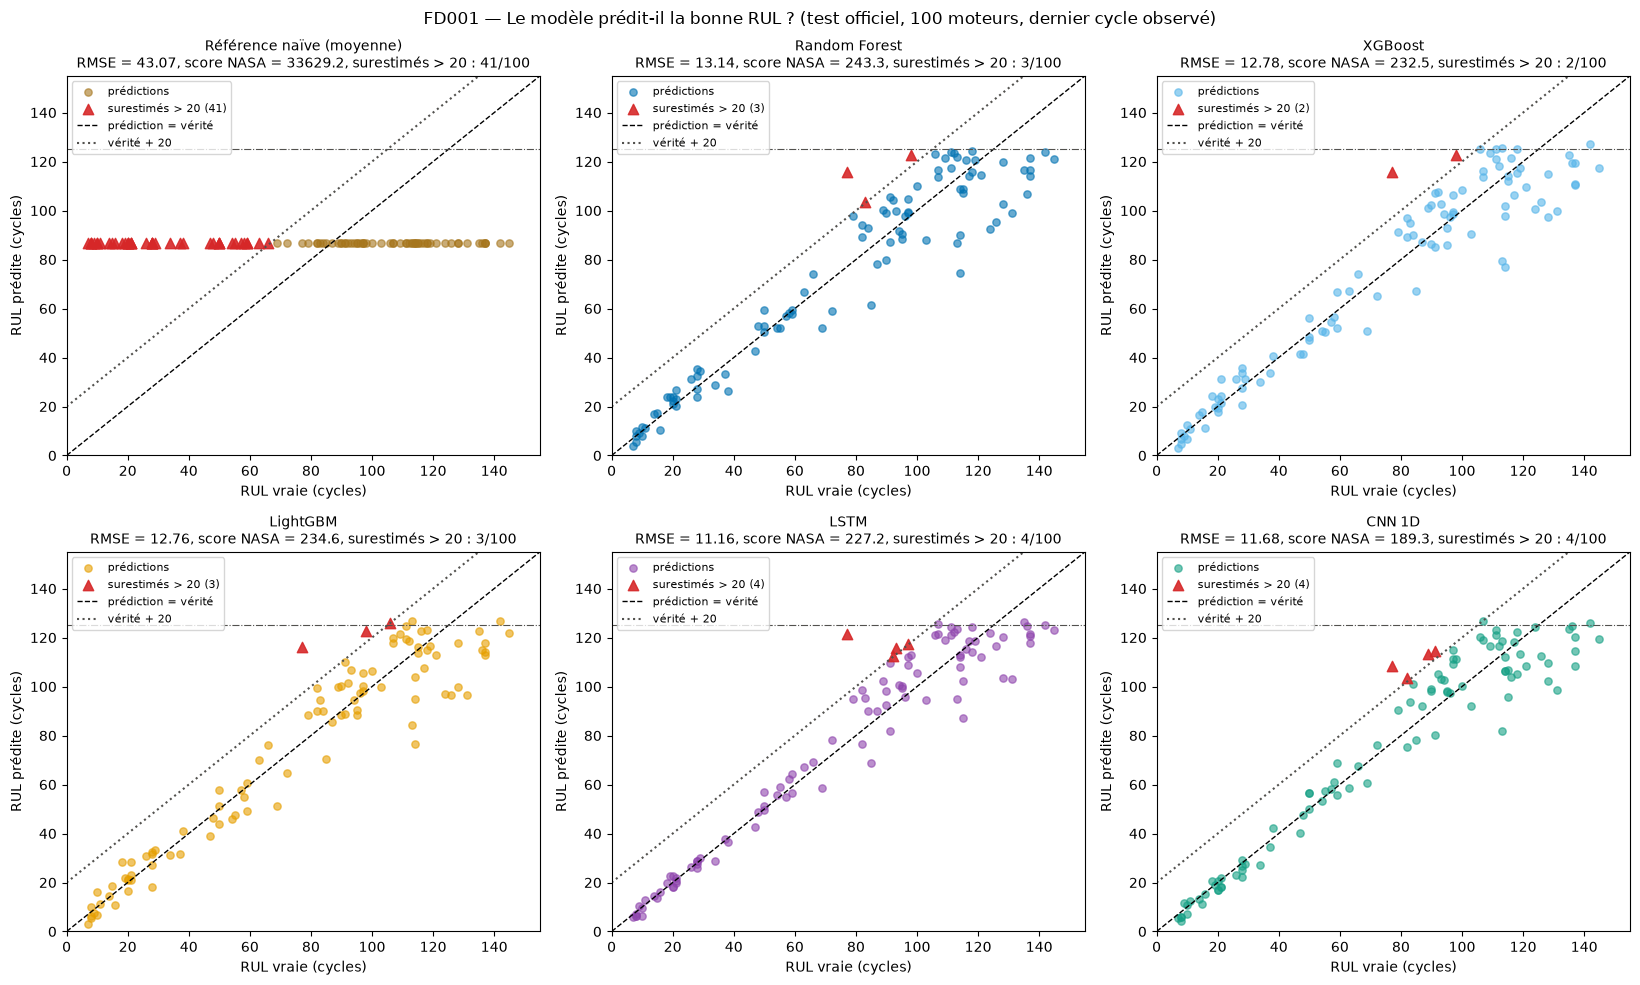

In [19]:
# --- Figure : RUL prédite contre vraie, test officiel ---
figure = fr.figure_predit_vs_vrai(evaluation, ensemble="test")
plt.show()

**Résidus selon la vraie RUL** : les modèles se trompent-ils surtout près de la panne (zone de décision) ou loin d'elle (effet du plafond) ? Résidu = prédit − vrai ; > 0 = surestimation. La référence naïve n'est pas tracée : ses résidus écraseraient l'échelle commune des autres cases.

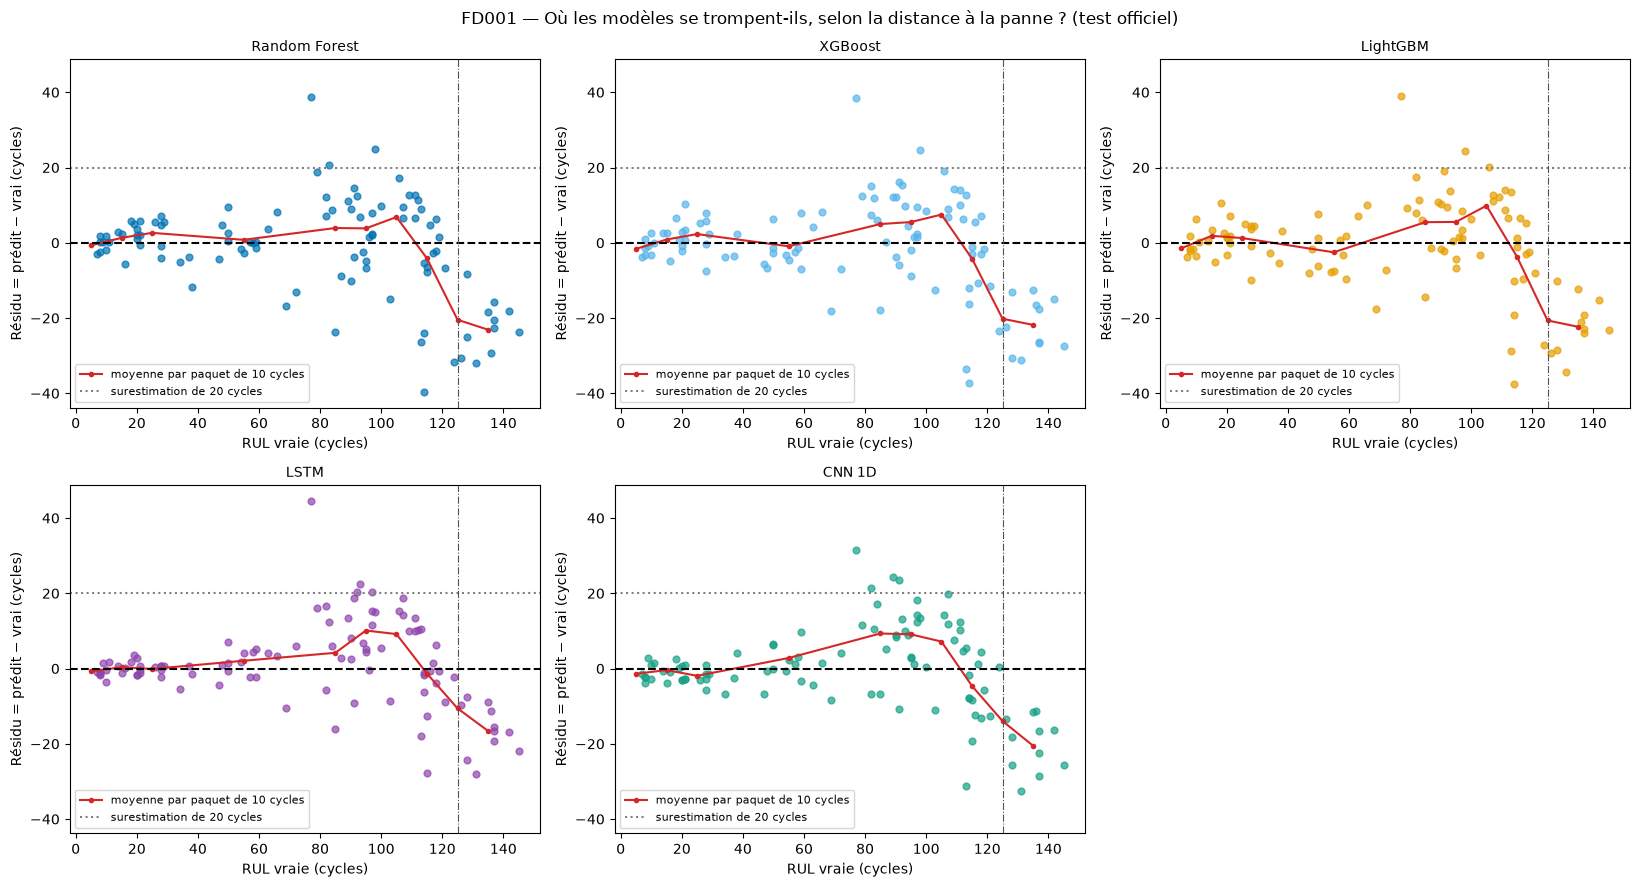

In [20]:
# --- Figure : résidus selon la vraie RUL, test officiel ---
figure = fr.figure_residus_selon_rul(evaluation, ensemble="test")
plt.show()

**Modèles contre baselines** (notebooks 01b, F.3 et 05, B.3) : un panneau par critère, jamais deux échelles sur le même axe. RMSE : barre = contre la RUL brute, losange = contre la RUL plafonnée, tiret = le plancher dû au plafond (1.1). Score NASA : échelle logarithmique, car les baselines constantes dépassent les modèles appris de plusieurs ordres de grandeur.

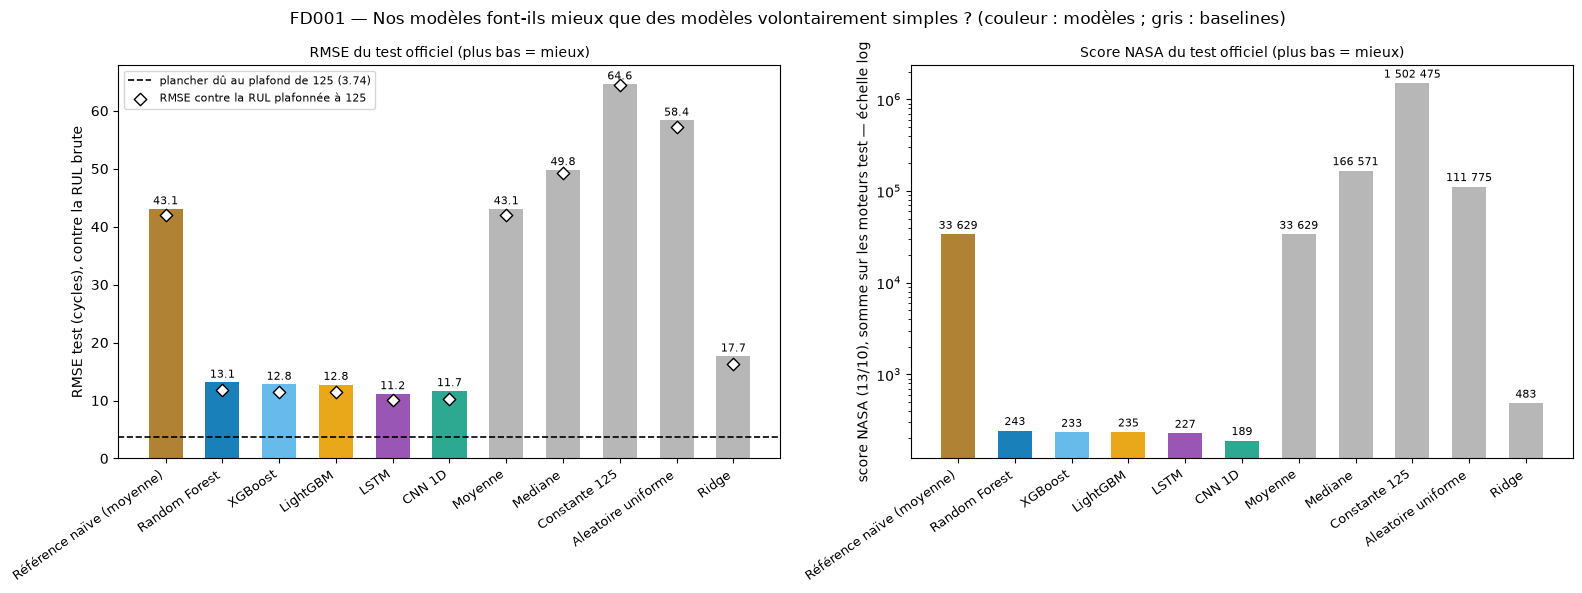

In [21]:
# --- Figure : RMSE et score NASA du test, modèles contre les 5 baselines ---
figure = fr.figure_barres_baselines(evaluation)
plt.show()

### 4.4 Où nous situer dans la littérature

**Le problème** (notebook 05, H) : beaucoup d'articles publient un RMSE sur le test C-MAPSS, mais tous ne mesurent pas exactement la même chose. Pour comparer honnêtement, il faut savoir (1) contre quelle vérité test l'erreur est calculée, (2) combien d'entraînements sont moyennés.

**Les articles retenus** (chiffres relus dans les articles eux-mêmes, recopiés dans `src/evaluation_sous_jeu.py`, jamais recalculés) :
- **Babu, Zhao, Li 2016** — *Deep Convolutional Neural Network Based Regression Approach for Estimation of Remaining Useful Life*, DASFAA 2016, LNCS 9642, p. 214-228, DOI [10.1007/978-3-319-32025-0_14](https://doi.org/10.1007/978-3-319-32025-0_14). Premier CNN sur C-MAPSS ; fenêtre de 15 cycles ; plafond de la RUL choisi par sous-jeu (valeur non donnée dans l'article).
- **Li, Ding, Sun 2018** — *Remaining useful life estimation in prognostics using deep convolution neural networks*, Reliability Engineering & System Safety 172 (2018), DOI [10.1016/j.ress.2017.11.021](https://doi.org/10.1016/j.ress.2017.11.021). DCNN ; fenêtre de 30 cycles et plafond de 125 sur FD001, moyenne de 10 entraînements. La version relue (prépublication de juin 2017) ne donne que FD001 : les chiffres FD002 à FD004 cités par d'autres articles ne sont pas repris.
- **Zhang, Song, Li 2022** — *Dual Aspect Self-Attention based on Transformer for Remaining Useful Life Prediction* (DAST), IEEE Transactions on Instrumentation and Measurement 71, DOI [10.1109/TIM.2022.3160561](https://doi.org/10.1109/TIM.2022.3160561). Fenêtre de 40 cycles sur FD001 et FD003, 60 sur FD002 et FD004, plafond 125, moyenne de 10 entraînements.
- **Huang, He, Sick 2023** — *Spatio-Temporal Attention Graph Neural Network for Remaining Useful Life Prediction* (STAGNN), CSCI 2023, arXiv:[2401.15964](https://arxiv.org/abs/2401.15964). Fenêtre de 50 cycles, plafond 125, moyenne de 10 essais ; la version STAGNN* normalise les capteurs **par régime de vol** (comme notre `src/sous_jeux.py` pour FD002 et FD004).

**La convention** : tous ces articles plafonnent les **étiquettes d'entraînement** ; **aucun ne dit si la vraie RUL du test est plafonnée** avant de calculer le RMSE. Nous donnons donc nos deux RMSE : contre la RUL brute (protocole officiel) et contre la RUL plafonnée à 125.

**Un indice** (notebook 05, H.1) : le plancher de la section 1.1. Un article qui publie, avec des étiquettes plafonnées, un RMSE **plus petit que ce plancher** n'a très probablement pas mesuré contre la RUL brute (il faudrait que son modèle prédise nettement plus de 125 pour les moteurs concernés) : c'est alors notre RMSE plafonné qu'il faut mettre en face. Sur un sous-jeu où le plancher est petit, l'indice ne tranche pas.

**Comment lire** : plus petit = mieux ; une case vide = non publié pour ce sous-jeu, ou absent de la version relue de l'article.

In [22]:
# --- Tableau de comparaison à la littérature (chiffres des articles recopiés, les nôtres calculés ci-dessus) ---
litterature = evaluation["litterature"]
display(litterature.set_index(["source", "modele"]).round(2))

# --- L'indice du plancher : quels articles publient moins que le plancher de ce sous-jeu ? ---
plancher = donnees["plancher_rmse_rul_brute"]
for indice in litterature.index:
    ligne = litterature.loc[indice]
    if ligne["source"] == "ce projet" or pd.isna(ligne["rmse_test"]):
        continue  # nos propres lignes, ou chiffre non publié pour ce sous-jeu
    if ligne["rmse_test"] < plancher:
        verdict = "sous le plancher : très probablement mesuré contre la RUL plafonnée"
    else:
        verdict = "au-dessus du plancher : l'indice ne tranche pas"
    print(f"{ligne['source']} ({ligne['modele']}) : {ligne['rmse_test']:.2f} ; plancher {plancher:.2f} → {verdict}")

fenetre                           entrainements      verite_test  rmse_test
source               modele                                                                                                                                                
Babu, Zhao, Li 2016  CNN                                                                             15                             non precise     non precisee      18.45
Li, Ding, Sun 2018   DCNN                                                                            30                           moyenne de 10     non precisee      12.61
Zhang, Song, Li 2022 DAST                                                                       40 / 60                           moyenne de 10     non precisee      11.43
Huang, He, Sick 2023 STAGNN* (norm. par regime)                                                      50                           moyenne de 10     non precisee      11.50
ce projet            Random Forest               1 cycle (capteurs lisses sur 5, ecart aux 20 premiers)                                       1  plafonnee a 125      11.84
                     Random Forest               1 cycle (capteurs lisses sur 5, ecart aux 20 premiers)                                       1            brute      13.14
                     XGBoost                     1 cycle (capteurs lisses sur 5, ecart aux 20 premiers)                                       1  plafonnee a 125      11.46
                     XGBoost                     1 cycle (capteurs lisses sur 5, ecart aux 20 premiers)                                       1            brute      12.78
                     LightGBM                    1 cycle (capteurs lisses sur 5, ecart aux 20 premiers)                                       1  plafonnee a 125      11.50
                     LightGBM                    1 cycle (capteurs lisses sur 5, ecart aux 20 premiers)                                       1            brute      12.76
                     LSTM                                              fenetre du reseau (notebook 04h)  moyenne de 5 reseaux (graines 42 a 46)  plafonnee a 125      10.09
                     LSTM                                              fenetre du reseau (notebook 04h)  moyenne de 5 reseaux (graines 42 a 46)            brute      11.16
                     CNN 1D                                            fenetre du reseau (notebook 04h)                                       1  plafonnee a 125      10.33
                     CNN 1D                                            fenetre du reseau (notebook 04h)                                       1            brute      11.68

Babu, Zhao, Li 2016 (CNN) : 18.45 ; plancher 3.74 → au-dessus du plancher : l'indice ne tranche pas
Li, Ding, Sun 2018 (DCNN) : 12.61 ; plancher 3.74 → au-dessus du plancher : l'indice ne tranche pas
Zhang, Song, Li 2022 (DAST) : 11.43 ; plancher 3.74 → au-dessus du plancher : l'indice ne tranche pas
Huang, He, Sick 2023 (STAGNN* (norm. par regime)) : 11.50 ; plancher 3.74 → au-dessus du plancher : l'indice ne tranche pas


**Ce qu'on peut dire, et ce qu'on ne peut pas dire** (notebook 05, H.3) :
- La convention des articles reste une **hypothèse** : ils ne l'écrivent pas.
- **Mise en garde générale** : les articles moyennent 10 entraînements ; nous en avons un seul par modèle (graine 42), sauf le LSTM, moyenne de 5 réseaux. Un bon chiffre isolé peut venir d'une graine favorable : il faudrait 10 graines pour une comparaison à armes égales. Un écart plus petit que la variation d'une graine à l'autre ne permet pas de dire que nous faisons mieux.

In [23]:
# --- Ce qu'on lit dans le test officiel (phrases construites à partir des chiffres ci-dessus) ---
meilleur_test = appris[0]
for cle in appris:
    if brute.loc[cle, "rmse"] < brute.loc[meilleur_test, "rmse"]:
        meilleur_test = cle
phrases = []
phrases.append(f"- Plus petit RMSE test (contre la RUL brute) : {evaluation['noms'][meilleur_test]}, "
               f"{brute.loc[meilleur_test, 'rmse']:.2f} cycles ({plafonnee.loc[meilleur_test, 'rmse']:.2f} contre la RUL "
               f"plafonnée), score NASA {brute.loc[meilleur_test, 'nasa_somme']:.1f}.")
phrases.append(f"- Ridge, régression linéaire : {brute.loc['Ridge', 'rmse']:.2f} ; référence naïve (moyenne) : "
               f"{brute.loc['Moyenne', 'rmse']:.2f}. Les écarts entre modèles sont testés en section 6.")
phrases.append(f"- Plancher dû au plafond : {plancher:.2f} cycles ; {donnees['nb_rul_vraie_sup_plafond']} moteurs test "
               f"sur {donnees['nb_moteurs_test']} ont une vraie RUL > 125 (section 1.1).")
# réseaux contre arbres au test : le test mesure, il ne choisit pas (règle 1)
reseaux_publies = []  # les réseaux disponibles sur ce sous-jeu
arbres_appris = []  # les 3 arbres (sans la référence naïve)
for cle in appris:
    if cle in inf.MODELES_RESEAUX:
        reseaux_publies.append(cle)
    else:
        arbres_appris.append(cle)
if len(reseaux_publies) > 0 and len(arbres_appris) > 0:
    meilleur_reseau = reseaux_publies[0]
    for cle in reseaux_publies:
        if brute.loc[cle, "rmse"] < brute.loc[meilleur_reseau, "rmse"]:
            meilleur_reseau = cle
    meilleur_arbre = arbres_appris[0]
    for cle in arbres_appris:
        if brute.loc[cle, "rmse"] < brute.loc[meilleur_arbre, "rmse"]:
            meilleur_arbre = cle
    validation_neufs = evaluation["validation"]["tableau"].set_index("cle")["rmse_decoupages_neufs_moyen"]
    comparaison_test = (f"{evaluation['noms'][meilleur_reseau]} {brute.loc[meilleur_reseau, 'rmse']:.2f} "
                        f"({plafonnee.loc[meilleur_reseau, 'rmse']:.2f} plafonnée) contre "
                        f"{evaluation['noms'][meilleur_arbre]} {brute.loc[meilleur_arbre, 'rmse']:.2f} "
                        f"({plafonnee.loc[meilleur_arbre, 'rmse']:.2f} plafonnée)")
    if not pd.isna(validation_neufs[meilleur_reseau]) and not pd.isna(validation_neufs[meilleur_arbre]):
        comparaison_validation = (f" ; en validation, sur les 3 découpages neufs : {validation_neufs[meilleur_reseau]:.2f} "
                                  f"contre {validation_neufs[meilleur_arbre]:.2f}")
    else:
        comparaison_validation = ""
    if brute.loc[meilleur_reseau, "rmse"] > brute.loc[meilleur_arbre, "rmse"]:
        phrases.append(f"- **Au test, aucun réseau ne fait mieux que le meilleur arbre** (RUL brute) : {comparaison_test}"
                       f"{comparaison_validation}. Les réseaux restent publiés : leurs réglages et l'ensemble ont été "
                       "retenus sur la validation, par des règles écrites avant (section 2), et le test ne sert jamais "
                       "à choisir (règle 1). Les écarter maintenant reviendrait à choisir sur le test. Si l'écart est "
                       "significatif ou non : section 6.")
    elif brute.loc[meilleur_reseau, "rmse"] < brute.loc[meilleur_arbre, "rmse"]:
        phrases.append(f"- Au test, le meilleur réseau fait mieux que le meilleur arbre (RUL brute) : {comparaison_test}"
                       f"{comparaison_validation}. Si l'écart est significatif ou non : section 6.")
    else:
        phrases.append(f"- Au test, le meilleur réseau et le meilleur arbre ont le même RMSE (RUL brute) : {comparaison_test}"
                       f"{comparaison_validation}.")
display(Markdown("**Ce qu'on lit (test officiel)**\n\n" + "\n".join(phrases)))

**Ce qu'on lit (test officiel)**

- Plus petit RMSE test (contre la RUL brute) : LSTM, 11.16 cycles (10.09 contre la RUL plafonnée), score NASA 227.2.
- Ridge, régression linéaire : 17.66 ; référence naïve (moyenne) : 43.07. Les écarts entre modèles sont testés en section 6.
- Plancher dû au plafond : 3.74 cycles ; 11 moteurs test sur 100 ont une vraie RUL > 125 (section 1.1).
- Au test, le meilleur réseau fait mieux que le meilleur arbre (RUL brute) : LSTM 11.16 (10.09 plafonnée) contre LightGBM 12.76 (11.50 plafonnée) ; en validation, sur les 3 découpages neufs : 7.38 contre 8.95. Si l'écart est significatif ou non : section 6.

## 5. Classification : « ce moteur tombe-t-il en panne dans les N prochains cycles ? »

**Question** : les modèles déclenchent-ils l'alerte maintenance à temps ?

**L'idée** (notebook 05, G.5 ; notebook 04b, approche 1, celle de `src/alertes.py` et de la démo) : en maintenance, la vraie question est souvent oui / non. On transforme chaque prédiction de RUL en **alerte** : alerte si la RUL prédite ≤ un seuil. La vérité est « positif » si la vraie RUL ≤ N. On étudie N = 15, 30 et 50 cycles.

**Les mesures** :
- **matrice de confusion** `vn / fp / fn / vp` : vrais négatifs (pas d'alerte, à raison), faux positifs (alerte inutile : coûteux), faux négatifs (alerte manquée : **dangereux**), vrais positifs ;
- **précision** = vp / (vp + fp) : parmi les alertes, la part de justes ; **rappel** = vp / (vp + fn) : parmi les moteurs à risque, la part détectée ; **F1** = moyenne harmonique des deux ;
- **AUC ROC** et **précision moyenne (AP)** : qualité du classement des moteurs du plus au moins urgent, tous seuils confondus (score : −RUL prédite) ;
- l'**accuracy** (part de bonnes réponses) est calculée mais trompe ici (5.1).

**Deux seuils** (notebook 04b, sections 3 et 5) : le seuil n'a pas de raison d'être égal à N. Le seuil « défaut » = N ; le seuil « choisi » est fixé sur les prédictions hors-pli de la **validation** : parmi les seuils qui donnent un rappel ≥ 0,95 (règle du notebook 05, G.5, `RAPPEL_MINIMUM`), celui qui a la meilleure précision (rappel d'abord, parce qu'un moteur proche de la panne laissé en vol est le cas grave). Il est ensuite appliqué tel quel au test, qui ne sert jamais à le choisir. **À trancher** : le notebook 04b (décision du 2026-11-04, reprise en section 13 de `02_choix_du_modele.ipynb`) exige un rappel ≥ 0,99 ; les deux règles coexistent dans la v2, la décision revient à l'équipe. Les réseaux n'ont pas de prédictions hors-pli enregistrées : seul leur seuil « défaut » est évalué.

**Piège à anticiper** (notebook 04b, section 1) : la validation contient **tous les cycles** de chaque moteur (beaucoup de cycles « en bonne santé »), le test **seulement le dernier cycle observé** de chaque moteur. La proportion de positifs n'est donc pas la même des deux côtés, et les précisions ne se comparent pas telles quelles.

**Comment lire** : un tableau par N. `R plis` = rappel moyen ± écart-type entre les 5 plis de validation. Au test, peu de moteurs sont positifs : un seul moteur manqué fait varier le rappel de plusieurs points.

In [24]:
# --- Classification : un tableau par N (test officiel, puis validation pour les modèles qui ont des prédictions hors-pli) ---
classification = evaluation["classification"]
for horizon in es.HORIZONS:
    sous_tableau = classification[classification["N"] == horizon]
    premiere = sous_tableau.iloc[0]  # la proportion de positifs ne dépend pas du modèle
    print(f"N = {horizon} : {int(premiere['test_nb_positifs'])} moteurs test positifs sur "
          f"{len(evaluation['test']['moteurs'])} ({100 * premiere['test_proportion_positifs']:.1f} %) ; "
          f"en validation, {100 * premiere['val_proportion_positifs']:.1f} % des lignes.")
    lignes = []
    for indice in sous_tableau.index:
        source = sous_tableau.loc[indice]
        ligne = {}
        ligne["modele"] = source["modele"]
        ligne["seuil"] = f"{source['seuil']:.1f} ({source['regle_seuil']})"
        ligne["test vp / fn / fp"] = f"{int(source['test_vp'])} / {int(source['test_fn'])} / {int(source['test_fp'])}"
        ligne["test rappel"] = round(float(source["test_rappel"]), 3)
        ligne["test précision"] = round(float(source["test_precision"]), 3)
        ligne["test F1"] = round(float(source["test_f1"]), 3)
        ligne["test AUC"] = round(float(source["test_auc_roc"]), 3)
        ligne["test AP"] = round(float(source["test_precision_moyenne"]), 3)
        ligne["val rappel"] = round(float(source["val_rappel"]), 3)
        ligne["val précision"] = round(float(source["val_precision"]), 3)
        if pd.isna(source["val_rappel_plis_moyenne"]):
            ligne["R plis"] = ""  # réseau : pas de prédictions hors-pli
        else:
            ligne["R plis"] = es.formater_moyenne_ecart(source["val_rappel_plis_moyenne"], source["val_rappel_plis_ecart_type"])
        lignes.append(ligne)
    display(pd.DataFrame(lignes).set_index("modele"))

N = 15 : 10 moteurs test positifs sur 100 (10.0 %) ; en validation, 7.8 % des lignes.


,seuil,test vp / fn / fp,test rappel,test précision,test F1,test AUC,test AP,val rappel,val précision,R plis
modele,,,,,,,,,,
Référence naïve (moyenne),15.0 (defaut (= N)),0 / 10 / 0,0.0,0.000,0.000,0.500,0.100,0.000,0.000,0.00 ± 0.00
Référence naïve (moyenne),87.3 (choisi sur validation),10 / 0 / 90,1.0,0.100,0.182,0.500,0.100,1.000,0.078,1.00 ± 0.00
Random Forest,15.0 (defaut (= N)),8 / 2 / 1,0.8,0.889,0.842,0.996,0.957,0.874,0.943,0.87 ± 0.02
Random Forest,17.3 (choisi sur validation),9 / 1 / 1,0.9,0.900,0.900,0.996,0.957,0.952,0.894,0.95 ± 0.01
XGBoost,15.0 (defaut (= N)),8 / 2 / 1,0.8,0.889,0.842,0.997,0.970,0.893,0.927,0.89 ± 0.02
XGBoost,17.1 (choisi sur validation),9 / 1 / 1,0.9,0.900,0.900,0.997,0.970,0.950,0.879,0.95 ± 0.01
LightGBM,15.0 (defaut (= N)),8 / 2 / 1,0.8,0.889,0.842,0.993,0.943,0.901,0.926,0.90 ± 0.02
LightGBM,16.9 (choisi sur validation),9 / 1 / 2,0.9,0.818,0.857,0.993,0.943,0.950,0.873,0.95 ± 0.01
LSTM,15.0 (defaut (= N)),10 / 0 / 0,1.0,1.000,1.000,1.000,1.000,NaN,NaN,


N = 30 : 25 moteurs test positifs sur 100 (25.0 %) ; en validation, 15.0 % des lignes.


,seuil,test vp / fn / fp,test rappel,test précision,test F1,test AUC,test AP,val rappel,val précision,R plis
modele,,,,,,,,,,
Référence naïve (moyenne),30.0 (defaut (= N)),0 / 25 / 0,0.00,0.000,0.000,0.500,0.250,0.000,0.000,0.00 ± 0.00
Référence naïve (moyenne),87.3 (choisi sur validation),25 / 0 / 75,1.00,0.250,0.400,0.500,0.250,1.000,0.150,1.00 ± 0.00
Random Forest,30.0 (defaut (= N)),21 / 4 / 2,0.84,0.913,0.875,0.994,0.981,0.899,0.958,0.90 ± 0.03
Random Forest,32.7 (choisi sur validation),23 / 2 / 2,0.92,0.920,0.920,0.994,0.981,0.950,0.929,0.95 ± 0.02
XGBoost,30.0 (defaut (= N)),20 / 5 / 0,0.80,1.000,0.889,0.996,0.989,0.907,0.960,0.91 ± 0.02
XGBoost,32.5 (choisi sur validation),23 / 2 / 1,0.92,0.958,0.939,0.996,0.989,0.950,0.923,0.95 ± 0.01
LightGBM,30.0 (defaut (= N)),21 / 4 / 0,0.84,1.000,0.913,0.997,0.992,0.908,0.950,0.91 ± 0.01
LightGBM,32.7 (choisi sur validation),24 / 1 / 2,0.96,0.923,0.941,0.997,0.992,0.950,0.915,0.95 ± 0.01
LSTM,30.0 (defaut (= N)),25 / 0 / 1,1.00,0.962,0.980,0.999,0.997,NaN,NaN,


N = 50 : 33 moteurs test positifs sur 100 (33.0 %) ; en validation, 24.7 % des lignes.


,seuil,test vp / fn / fp,test rappel,test précision,test F1,test AUC,test AP,val rappel,val précision,R plis
modele,,,,,,,,,,
Référence naïve (moyenne),50.0 (defaut (= N)),0 / 33 / 0,0.000,0.000,0.000,0.500,0.330,0.000,0.000,0.00 ± 0.00
Référence naïve (moyenne),87.3 (choisi sur validation),33 / 0 / 67,1.000,0.330,0.496,0.500,0.330,1.000,0.247,1.00 ± 0.00
Random Forest,50.0 (defaut (= N)),29 / 4 / 0,0.879,1.000,0.935,0.994,0.989,0.908,0.965,0.91 ± 0.03
Random Forest,54.3 (choisi sur validation),32 / 1 / 3,0.970,0.914,0.941,0.994,0.989,0.951,0.926,0.95 ± 0.02
XGBoost,50.0 (defaut (= N)),32 / 1 / 0,0.970,1.000,0.985,0.998,0.996,0.927,0.963,0.93 ± 0.02
XGBoost,52.4 (choisi sur validation),32 / 1 / 4,0.970,0.889,0.928,0.998,0.996,0.950,0.946,0.95 ± 0.01
LightGBM,50.0 (defaut (= N)),31 / 2 / 3,0.939,0.912,0.925,0.996,0.992,0.928,0.958,0.93 ± 0.02
LightGBM,52.2 (choisi sur validation),32 / 1 / 4,0.970,0.889,0.928,0.996,0.992,0.950,0.942,0.95 ± 0.02
LSTM,50.0 (defaut (= N)),31 / 2 / 0,0.939,1.000,0.969,0.999,0.997,NaN,NaN,


### 5.1 Pourquoi l'accuracy trompe ici

**L'idée** (notebook 04b, section 6) : un « modèle » qui ne déclenche **jamais** d'alerte a une excellente accuracy dès que les positifs sont rares, et un rappel de 0. La baseline « Constante 125 » au seuil N est exactement ce modèle (elle prédit toujours 125, au-dessus de tout N étudié) : son accuracy est la part de négatifs.

In [25]:
# --- Accuracy d'un modèle qui n'alerte jamais (Constante 125, seuil = N), à côté de son rappel ---
lignes = []
for horizon in es.HORIZONS:
    jamais = classification[(classification["N"] == horizon) & (classification["cle"] == "Constante 125")
                            & (classification["regle_seuil"] == "defaut (= N)")].iloc[0]
    ligne = {}
    ligne["N"] = horizon
    ligne["accuracy validation"] = round(float(jamais["val_accuracy"]), 3)
    ligne["accuracy test"] = round(float(jamais["test_accuracy"]), 3)
    ligne["rappel test"] = round(float(jamais["test_rappel"]), 3)
    ligne["alertes déclenchées au test"] = int(jamais["test_vp"] + jamais["test_fp"])
    lignes.append(ligne)
display(pd.DataFrame(lignes).set_index("N"))

,accuracy validation,accuracy test,rappel test,alertes déclenchées au test
N,,,,
15,0.922,0.90,0.0,0
30,0.850,0.75,0.0,0
50,0.753,0.67,0.0,0


### 5.2 Courbes ROC et précision-rappel (N = 30)

**Comment lire** (notebook 04b, section 7) : une courbe par modèle, la baseline aléatoire en gris. À gauche, la courbe ROC : taux de vrais positifs contre taux de faux positifs quand le seuil varie ; AUC en légende (1 = parfait, 0,5 = hasard). À droite, la courbe précision-rappel : la précision obtenue pour chaque niveau de rappel exigé ; précision moyenne (AP) en légende ; la ligne horizontale du hasard est la proportion de positifs. Les deux courbes sont tracées sur le test (un point par moteur).

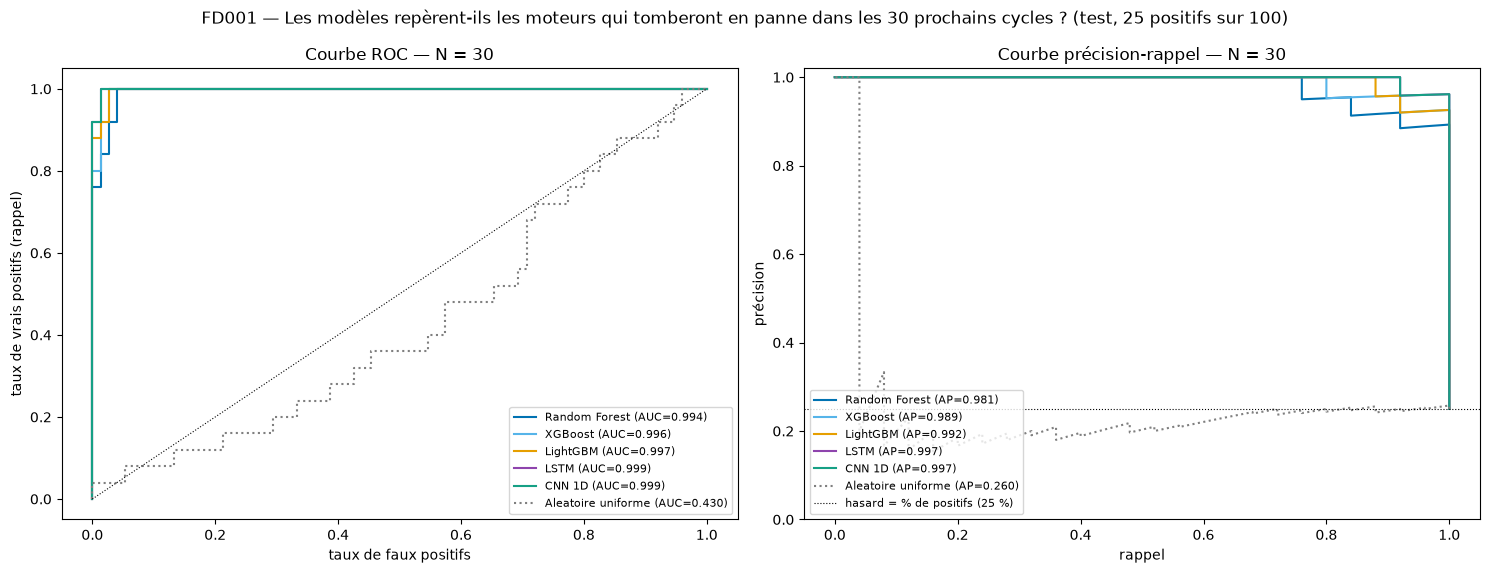

In [26]:
# --- Figure : courbes ROC et précision-rappel au test, N = 30 (deux panneaux) ---
figure = fr.figure_roc_precision_rappel(evaluation, horizon=es.HORIZON_MATRICES)
plt.show()

**À lire avec la figure** : au test, peu de moteurs sont proches de la panne (de l'ordre de 10 sur 100 pour N = 15), donc la courbe ROC est en escalier et l'AUC paraît souvent très bonne. Le notebook 04b l'a mesuré en validation : l'AUC valait 0,977 à 0,996 pour les 3 approches comparées et ne les départageait pas, alors que la courbe précision-rappel (ligne du hasard = proportion de positifs) montre le coût en précision de chaque niveau de rappel. D'où les deux panneaux côte à côte.

### 5.3 Matrices de confusion (N = 30)

**Comment lire** (notebook 04b, section 7) : une matrice par modèle, au test. Lignes = vérité, colonnes = alerte ou non. La case « faux négatif » (moteur laissé voler alors qu'il est à moins de N cycles de la panne) est le cas grave ; « faux positif » = moteur retiré trop tôt. Seuil utilisé : celui choisi sur la validation quand il existe (arbres), sinon N (réseaux) ; il est rappelé dans le titre de chaque case et listé sous la figure.

N = 30 est la proposition du plan (section 12), à confirmer par l'équipe ; les tableaux de la section 5 donnent les trois N.

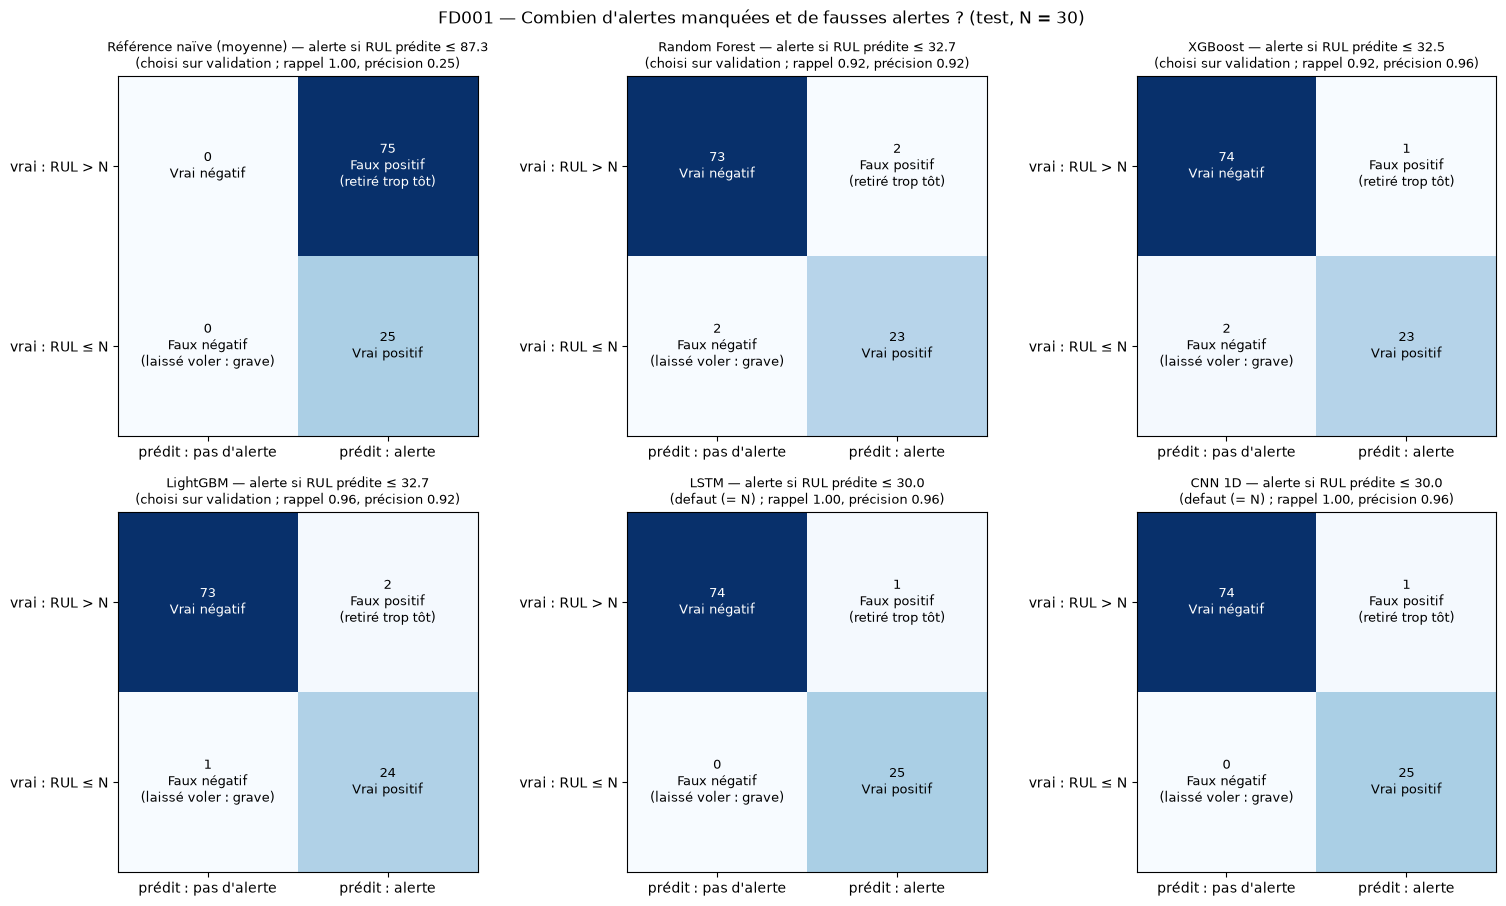

Référence naïve (moyenne) : seuil 87.3 cycles (choisi sur validation)
Random Forest : seuil 32.7 cycles (choisi sur validation)
XGBoost : seuil 32.5 cycles (choisi sur validation)
LightGBM : seuil 32.7 cycles (choisi sur validation)
LSTM : seuil 30.0 cycles (defaut (= N))
CNN 1D : seuil 30.0 cycles (defaut (= N))


In [27]:
# --- Figure : matrices de confusion au test, N = 30, une par modèle ---
figure = fr.figure_matrices_confusion(evaluation, horizon=es.HORIZON_MATRICES)
plt.show()
for cle in evaluation["modeles"]:
    seuil = evaluation["seuils_matrices"][cle]
    print(f"{evaluation['noms'][cle]} : seuil {seuil['seuil']:.1f} cycles ({seuil['regle_seuil']})")

### 5.4 Chaque métrique de classification : gardée ou écartée

Verdicts du notebook 04b (section 10), dont les chiffres portaient sur l'ancien XGBoost Phase 3 :

| Métrique | Verdict | Pourquoi |
|---|---|---|
| Matrice de confusion | **gardée** | seule vue qui sépare les faux négatifs (cas grave) des faux positifs (coût de maintenance). |
| Accuracy | **gardée en information, écartée comme critère** | un modèle qui ne déclenche jamais d'alerte a une accuracy élevée et un rappel de 0 (5.1). Toujours affichée avec la proportion de positifs. |
| Précision | **gardée** | mesure le coût des fausses alertes sous la contrainte de rappel. |
| Rappel | **gardée, prioritaire** | un moteur proche de la panne manqué est le cas grave ; c'est la contrainte qui fixe le seuil. |
| F1 | **gardée pour comparer, pas pour décider** | il pèse précision et rappel de façon symétrique, alors que le projet privilégie le rappel. |
| Courbe ROC + AUC | **gardée, peu discriminante** | elle confirme que le classement des moteurs est bon, elle ne départage pas les modèles (5.2). |
| Courbe précision-rappel + AP | **gardée, plus informative** | la ligne de base du hasard est la proportion de positifs ; elle montre le coût en précision de chaque rappel exigé. |

**Approche 2, classifieurs dédiés** (`LogisticRegression`, `XGBClassifier`, notebook 04b) : non refaite ici ; son résumé, et le test apparié qui la compare à l'approche par régression sur FD001, sont dans `02_choix_du_modele.ipynb`.

In [28]:
# --- Ce qu'on lit en classification à N = 30 (phrases construites à partir des chiffres ci-dessus) ---
sous_tableau = classification[classification["N"] == es.HORIZON_MATRICES]
phrases = []
for cle in evaluation["modeles"]:
    seuil = evaluation["seuils_matrices"][cle]  # celui de la matrice de confusion (choisi sur validation, sinon N)
    ligne = sous_tableau[(sous_tableau["cle"] == cle) & (sous_tableau["regle_seuil"] == seuil["regle_seuil"])].iloc[0]
    phrases.append(f"- {evaluation['noms'][cle]} (seuil {seuil['seuil']:.1f}, {seuil['regle_seuil']}) : "
                   f"{int(ligne['test_vp'])} moteurs à risque détectés sur {int(ligne['test_nb_positifs'])}, "
                   f"{int(ligne['test_fn'])} alerte(s) manquée(s), {int(ligne['test_fp'])} fausse(s) alerte(s).")
display(Markdown(f"**Ce qu'on lit (classification, N = {es.HORIZON_MATRICES}, test)**\n\n" + "\n".join(phrases)))

**Ce qu'on lit (classification, N = 30, test)**

- Référence naïve (moyenne) (seuil 87.3, choisi sur validation) : 25 moteurs à risque détectés sur 25, 0 alerte(s) manquée(s), 75 fausse(s) alerte(s).
- Random Forest (seuil 32.7, choisi sur validation) : 23 moteurs à risque détectés sur 25, 2 alerte(s) manquée(s), 2 fausse(s) alerte(s).
- XGBoost (seuil 32.5, choisi sur validation) : 23 moteurs à risque détectés sur 25, 2 alerte(s) manquée(s), 1 fausse(s) alerte(s).
- LightGBM (seuil 32.7, choisi sur validation) : 24 moteurs à risque détectés sur 25, 1 alerte(s) manquée(s), 2 fausse(s) alerte(s).
- LSTM (seuil 30.0, defaut (= N)) : 25 moteurs à risque détectés sur 25, 0 alerte(s) manquée(s), 1 fausse(s) alerte(s).
- CNN 1D (seuil 30.0, defaut (= N)) : 25 moteurs à risque détectés sur 25, 0 alerte(s) manquée(s), 1 fausse(s) alerte(s).

## 6. Comparaison des modèles

**Question** : les écarts entre modèles sont-ils réels, moteur par moteur ?

**Ce qu'on fait** (notebook 05, G.6 ; protocole §8) : on compare les modèles disponibles et Ridge **deux à deux**, moteur par moteur (test apparié). **Règle écrite avant les résultats** (`comparer_modeles_par_paires`, `src/evaluation.py`) :

> A est déclaré meilleur que B si la p-valeur de Wilcoxon bilatérale, **multipliée par le nombre de paires** (correction de Bonferroni), est < 0,05 et que la différence moyenne A − B est négative. Sinon : pas de différence significative. Les p-valeurs du test t sont rapportées à côté.

**Pourquoi apparié** : les deux modèles prédisent les mêmes moteurs ; on compare leurs erreurs moteur par moteur, ce qui retire la difficulté propre à chaque moteur (un moteur difficile l'est pour les deux).

**Trois jeux de valeurs appariées** : sur le test, l'erreur absolue de chaque moteur test ; en validation, le RMSE hors-pli de chaque moteur d'entraînement (arbres, référence naïve et Ridge seulement : les réseaux n'ont pas de prédictions hors-pli enregistrées) ; pour information, le RMSE des 5 plis (avec 5 paires seulement, la p-valeur de Wilcoxon bilatérale ne peut pas descendre sous 0,0625 : aucun écart ne peut y être significatif).

**Comment lire** : `difference_moyenne` = A − B (négatif = A se trompe moins) ; `A meilleur sur` = nombre de moteurs où A fait mieux ; `p Wilcoxon corrigée` = p-valeur multipliée par le nombre de paires (plafonnée à 1).

In [29]:
# --- Comparaisons appariées : test (erreur absolue par moteur test) ---
COLONNES_COMPARAISONS = {"modele_a": "A", "modele_b": "B", "n": "n", "difference_moyenne": "difference_moyenne",
                         "nb_unites_a_meilleur": "A meilleur sur", "p_t": "p t", "p_wilcoxon": "p Wilcoxon",
                         "p_wilcoxon_bonferroni": "p Wilcoxon corrigée", "conclusion": "conclusion"}
comparaisons = evaluation["comparaisons"]
for jeu, titre in [("test", "Test officiel : erreur absolue de chaque moteur test"),
                   ("validation", "Validation : RMSE hors-pli de chaque moteur d'entraînement"),
                   ("plis", "Pour information : RMSE des 5 plis (5 valeurs appariées par paire de modèles : jamais significatif)")]:
    tableau = comparaisons[jeu]
    if tableau is None:
        print(f"{titre} : moins de deux modèles comparables.")
        continue
    print(f"{titre} — {int(tableau['nb_comparaisons'].iloc[0])} paires (correction de Bonferroni)")
    affiche = tableau[list(COLONNES_COMPARAISONS.keys())].rename(columns=COLONNES_COMPARAISONS)
    display(affiche.round(4))

Test officiel : erreur absolue de chaque moteur test — 21 paires (correction de Bonferroni)


,A,B,n,difference_moyenne,A meilleur sur,p t,p Wilcoxon,p Wilcoxon corrigée,conclusion
0,Référence naïve (moyenne),Random Forest,100,26.4452,17,0.0000,0.0000,0.0000,Random Forest meilleur
1,Référence naïve (moyenne),XGBoost,100,26.5298,19,0.0000,0.0000,0.0000,XGBoost meilleur
2,Référence naïve (moyenne),LightGBM,100,26.6064,17,0.0000,0.0000,0.0000,LightGBM meilleur
3,Référence naïve (moyenne),LSTM,100,28.0923,18,0.0000,0.0000,0.0000,LSTM meilleur
4,Référence naïve (moyenne),CNN 1D,100,27.3401,21,0.0000,0.0000,0.0000,CNN 1D meilleur
5,Référence naïve (moyenne),Ridge,100,21.7326,22,0.0000,0.0000,0.0000,Ridge meilleur
6,Random Forest,XGBoost,100,0.0847,57,0.8326,0.4054,1.0000,pas de difference significative
7,Random Forest,LightGBM,100,0.1612,50,0.6924,0.8770,1.0000,pas de difference significative
8,Random Forest,LSTM,100,1.6472,36,0.0367,0.0100,0.2103,pas de difference significative
9,Random Forest,CNN 1D,100,0.8949,48,0.2632,0.5917,1.0000,pas de difference significative


Validation : RMSE hors-pli de chaque moteur d'entraînement — 10 paires (correction de Bonferroni)


,A,B,n,difference_moyenne,A meilleur sur,p t,p Wilcoxon,p Wilcoxon corrigée,conclusion
0,Référence naïve (moyenne),Random Forest,100,32.4716,0,0.0000,0.0000,0.0000,Random Forest meilleur
1,Référence naïve (moyenne),XGBoost,100,33.0422,0,0.0000,0.0000,0.0000,XGBoost meilleur
2,Référence naïve (moyenne),LightGBM,100,33.1105,0,0.0000,0.0000,0.0000,LightGBM meilleur
3,Référence naïve (moyenne),Ridge,100,25.2010,0,0.0000,0.0000,0.0000,Ridge meilleur
4,Random Forest,XGBoost,100,0.5707,41,0.0002,0.0019,0.0190,XGBoost meilleur
5,Random Forest,LightGBM,100,0.6389,37,0.0001,0.0005,0.0046,LightGBM meilleur
6,Random Forest,Ridge,100,-7.2705,99,0.0000,0.0000,0.0000,Random Forest meilleur
7,XGBoost,LightGBM,100,0.0682,45,0.1584,0.0881,0.8812,pas de difference significative
8,XGBoost,Ridge,100,-7.8412,100,0.0000,0.0000,0.0000,XGBoost meilleur
9,LightGBM,Ridge,100,-7.9095,100,0.0000,0.0000,0.0000,LightGBM meilleur


Pour information : RMSE des 5 plis (5 valeurs appariées par paire de modèles : jamais significatif) — 10 paires (correction de Bonferroni)


,A,B,n,difference_moyenne,A meilleur sur,p t,p Wilcoxon,p Wilcoxon corrigée,conclusion
0,Référence naïve (moyenne),Random Forest,5,31.7429,0,0.0000,0.0625,0.625,pas de difference significative
1,Référence naïve (moyenne),XGBoost,5,32.5652,0,0.0000,0.0625,0.625,pas de difference significative
2,Référence naïve (moyenne),LightGBM,5,32.6340,0,0.0000,0.0625,0.625,pas de difference significative
3,Référence naïve (moyenne),Ridge,5,24.7413,0,0.0000,0.0625,0.625,pas de difference significative
4,Random Forest,XGBoost,5,0.8223,0,0.0033,0.0625,0.625,pas de difference significative
5,Random Forest,LightGBM,5,0.8911,0,0.0075,0.0625,0.625,pas de difference significative
6,Random Forest,Ridge,5,-7.0016,5,0.0000,0.0625,0.625,pas de difference significative
7,XGBoost,LightGBM,5,0.0688,1,0.2283,0.3125,1.000,pas de difference significative
8,XGBoost,Ridge,5,-7.8239,5,0.0000,0.0625,0.625,pas de difference significative
9,LightGBM,Ridge,5,-7.8927,5,0.0000,0.0625,0.625,pas de difference significative


### 6.1 Figure : l'erreur de chaque moteur test, modèle par modèle

**Comment lire** : un point par moteur test et par modèle (erreur absolue au dernier cycle) ; les points d'un même moteur sont reliés d'un modèle à l'autre (gris très clair) : c'est sur ces différences, moteur par moteur, que porte le test, pas sur les deux moyennes. Au-dessus de chaque modèle : son erreur moyenne et la p-valeur de Wilcoxon corrigée contre le modèle de plus petite erreur moyenne. La référence naïve est hors échelle (sa moyenne est donnée dans le titre).

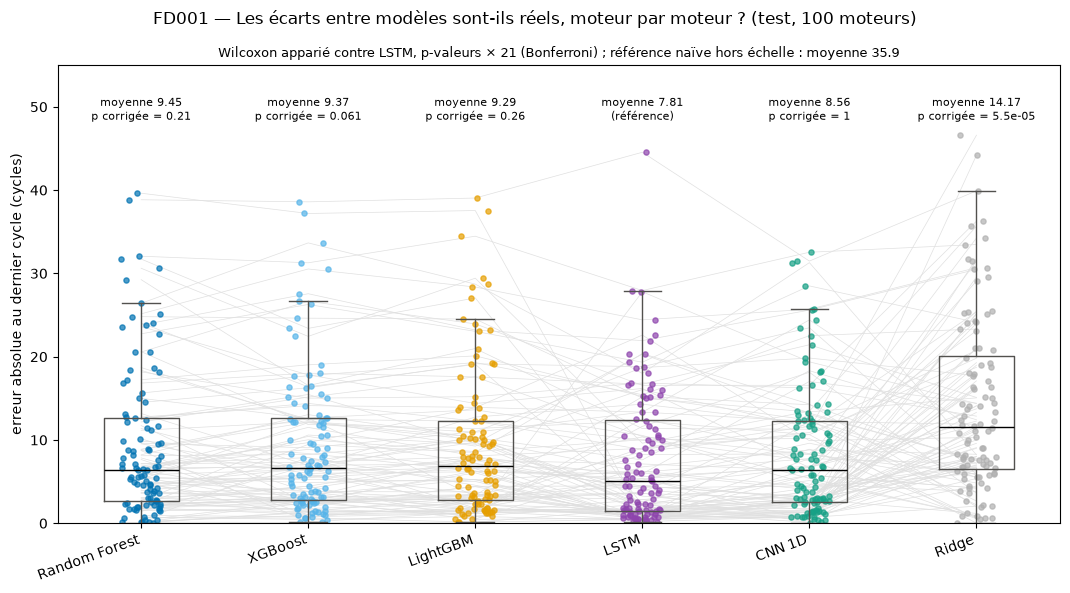

In [30]:
# --- Figure : erreur par moteur test, avec les p-valeurs des comparaisons appariées ---
figure = fr.figure_erreur_par_moteur(evaluation)
plt.show()

In [31]:
# --- Ce qu'on lit dans les comparaisons (phrases construites à partir des tableaux ci-dessus) ---
noms_appris = []  # noms affichés des modèles qui apprennent
for cle in appris:
    noms_appris.append(evaluation["noms"][cle])
phrases = []
for jeu, libelle in [("test", "sur le test"), ("validation", "en validation")]:
    tableau = comparaisons[jeu]
    if tableau is None:
        continue
    paires_appris = 0
    significatives = []
    for indice in tableau.index:
        paire = tableau.loc[indice]
        if paire["modele_a"] in noms_appris and paire["modele_b"] in noms_appris:
            paires_appris = paires_appris + 1
            if paire["conclusion"] != "pas de difference significative":
                significatives.append(f"{paire['modele_a']} contre {paire['modele_b']} : {paire['conclusion']} "
                                      f"(p corrigée {paire['p_wilcoxon_bonferroni']:.2g})")
    if paires_appris == 0:
        continue
    if len(significatives) == 0:
        phrases.append(f"- {libelle.capitalize()}, aucune des {paires_appris} paires entre modèles qui apprennent "
                       "n'est significative après correction : ces données ne suffisent pas à les départager.")
    else:
        phrases.append(f"- {libelle.capitalize()}, {len(significatives)} paire(s) significative(s) sur {paires_appris} "
                       "entre modèles qui apprennent : " + " ; ".join(significatives) + ".")
# les modèles qui apprennent contre Ridge, sur le test
battent_ridge = []
tableau = comparaisons["test"]
for indice in tableau.index:
    paire = tableau.loc[indice]
    if paire["modele_b"] == "Ridge" and paire["modele_a"] in noms_appris and paire["conclusion"] == f"{paire['modele_a']} meilleur":
        battent_ridge.append(paire["modele_a"])
liste_battent_ridge = "aucun"
if len(battent_ridge) > 0:
    liste_battent_ridge = ", ".join(battent_ridge)
phrases.append(f"- Sur le test, {len(battent_ridge)} modèle(s) qui apprennent sur {len(noms_appris)} battent Ridge "
               f"significativement : {liste_battent_ridge}.")
display(Markdown("**Ce qu'on lit (comparaisons appariées)**\n\n" + "\n".join(phrases)))

**Ce qu'on lit (comparaisons appariées)**

- Sur le test, aucune des 10 paires entre modèles qui apprennent n'est significative après correction : ces données ne suffisent pas à les départager.
- En validation, 2 paire(s) significative(s) sur 3 entre modèles qui apprennent : Random Forest contre XGBoost : XGBoost meilleur (p corrigée 0.019) ; Random Forest contre LightGBM : LightGBM meilleur (p corrigée 0.0046).
- Sur le test, 5 modèle(s) qui apprennent sur 5 battent Ridge significativement : Random Forest, XGBoost, LightGBM, LSTM, CNN 1D.

### 6.2 Ce que le protocole demande et qui n'est pas fait ici

Règle 11 d'`AGENTS.md` : signaler de soi-même chaque étape du protocole qui manque. La liste ci-dessous est produite par `evaluer_sous_jeu` pour ce sous-jeu. À savoir aussi (notebook 05, G.7) : **règle 1.3 du protocole**, la mise à l'échelle min-max (et, pour les réseaux, celle de l'écart à l'état initial) est apprise sur tout le train **avant** la validation croisée, pas dans chaque pli (aucune information de la cible n'y entre, mais les moteurs de validation contribuent aux bornes).

**Limites et points de méthode à connaître** (notebook 04a, section 11, toujours valables ici) :
- **Validation ≠ test.** Validation : toutes les lignes, cible plafonnée. Test : un point par moteur (dernier cycle), vérité non plafonnée. Les tranches du test ont des effectifs petits : leurs chiffres sont indicatifs.
- **Écart-type entre plis** : `np.std` avec ddof = 0, comme en Phase 3 ; avec ddof = 1, les valeurs seraient environ 12 % plus grandes (5 plis).
- **XGBoost n'est pas strictement déterministe d'un environnement à l'autre** (`docs/03_modelisation.md`) : sur FD001, le XGBoost final donne 12,78 au test sur la machine qui a généré ces notebooks et 12,73 sur celle de Matisse (même code, 1 cœur). Les versions des bibliothèques sont affichées en tête du notebook ; `requirements.txt` ne les fixe pas. L'écart reste à trancher par l'équipe.
- **Baseline aléatoire** : un seul tirage (graine fixée) ; suffisant pour une borne basse, pas pour des statistiques fines.

In [32]:
# --- Les étapes du protocole non faites ici, pour ce sous-jeu ---
for manque in evaluation["non_fait"]:
    print("-", manque)

- Erreur sur les moteurs d'entraînement (protocole §3 et §5.1) : calculée pour les arbres et les baselines (section 3.1), pas pour LSTM, CNN 1D (il faudrait réentraîner les réseaux pli par pli, ce qui est interdit ici : calcul de nuit du 04h).
- LSTM, CNN 1D : validation croisée du notebook 04h sur 3 découpages neufs (graines 1000 à 1002), pas sur les plis des arbres, et sans prédictions hors-pli enregistrées. Donc : pas de test apparié arbres contre réseaux en validation, pas de tranches de RUL ni de seuil d'alerte choisi en validation pour les réseaux (seuil par défaut N) ; les moyennes arbres / réseaux sont aussi données sur les 3 mêmes découpages neufs (colonne « RMSE découpages neufs »), comparables mais pas appariées.
- Classifieur dédié (protocole §4, approche 2) : non refait ici ; résumé dans 02_choix_du_modele (notebook 04b, FD001).
- Courbes d'apprentissage et de validation, optimisation des hyperparamètres (§5, §6) : faites sur FD001 seulement (02_choix_du_modele) ; réglages

## 7. Vérifier un moteur

**Question** : la démo affiche-t-elle bien ce que le code recalcule depuis les données brutes ?

**Le principe** (notebook 05, J) : les modèles ont appris uniquement sur `train_FD00X.txt`. On prend le moteur `MOTEUR` de `test_FD00X.txt` ; à chaque vol (un cycle) t, chaque modèle ne reçoit que les mesures des vols 1 à t, comme en service, préparées avec ce qui a été appris sur le train. La vraie RUL, lue dans le fichier `RUL_FD00X.txt` de la NASA, n'est utilisée qu'après, pour comparer.

**La preuve n'est jamais circulaire** (principe 3 du plan) : `verifier_moteur` repart des mesures brutes et **ne lit jamais** `sorties/predictions/`, les fichiers qu'affiche la démo. Ensuite seulement, `comparer_aux_fichiers_demo` ouvre ces fichiers et compare, cycle par cycle : les deux doivent être identiques (écart ≤ 1e-4 cycle). Un test automatique le vérifie aussi sur les 4 sous-jeux (`tests/test_evaluation_sous_jeu.py`).

**Ce qu'on fait** : (1) on recalcule la prédiction de chaque modèle à **chaque** cycle du moteur (c'est la courbe que trace la démo, notebook 03b, F.7) ; (2) au dernier cycle observé, on affiche la prédiction, la vraie RUL, l'écart et le statut d'alerte ; (3) on trace la courbe avec la vérité ; (4) on compare aux fichiers de la démo.

In [33]:
# --- (1) Prédiction recalculée à chaque cycle depuis data/test_FD00X.txt (src/evaluation_sous_jeu.py, verifier_moteur) ---
debut = time.perf_counter()
# inference : l'objet de la section 2.1 (modèles chargés, ou arbres réentraînés si ENTRAINER = True)
verification = es.verifier_moteur(SOUS_JEU, MOTEUR, inference=inference)
duree_verification = time.perf_counter() - debut
print(f"Moteur {MOTEUR} de test_{SOUS_JEU}.txt : {verification['nb_cycles']} cycles observés, "
      f"{len(verification['modeles'])} modèles recalculés à chaque cycle en {duree_verification:.1f} s.")
print("Source :", verification["source"])
if ENTRAINER:
    print("ENTRAINER = True : la référence naïve et les 3 arbres utilisés ici sont ceux réentraînés en section 2.1 "
          "(les réseaux viennent toujours de models/04h/).")
for cle in verification["indisponibles"]:
    if evaluation["absents"].get(cle) == es.RAISON_SANS_RESEAU:
        print(f"{es.nom_affiche(cle)} : {es.RAISON_SANS_RESEAU}.")  # absent par décision (section 2)
        continue
    print(f"{es.nom_affiche(cle)} indisponible : {verification['indisponibles'][cle]}")

Moteur 42 de test_FD001.txt : 156 cycles observés, 6 modèles recalculés à chaque cycle en 6.2 s.
Source : data/test_FD001.txt (mesures brutes), data/RUL_FD001.txt (vérité), modèles de models/ ; aucun fichier de sorties/predictions/ lu


**Révéler la vérité** (notebook 05, J.4) : la vraie RUL au dernier vol (`RUL_<SOUS_JEU>.txt`), l'écart de chaque modèle (positif = surestimation, le cas dangereux) et son statut d'alerte. **Règle d'alerte** (celle de `classer_alerte`, `src/alertes.py`, et de la démo) : le modèle alerte si sa RUL prédite ≤ 30 ; il aurait dû alerter si la vraie RUL ≤ 30. Les modèles ont appris une cible plafonnée à 125 : si la vraie RUL dépasse 125, une prédiction plus basse (écart négatif) est attendue.

In [34]:
# --- (2) Au dernier cycle observé : prédiction, vérité, écart et statut d'alerte de chaque modèle ---
print(f"Vraie RUL du moteur {MOTEUR} au dernier cycle observé (RUL_{SOUS_JEU}.txt) : {verification['rul_finale']:.0f} cycles")
display(verification["dernier_cycle"].drop(columns=["cle"]).set_index("modele").round(2))

Vraie RUL du moteur 42 au dernier cycle observé (RUL_FD001.txt) : 10 cycles


,rul_predite,rul_vraie,ecart,alerte,statut_alerte
modele,,,,,
Référence naïve (moyenne),86.83,10.0,76.83,False,ALERTE MANQUEE
Random Forest,11.76,10.0,1.76,True,alerte correcte
XGBoost,12.62,10.0,2.62,True,alerte correcte
LightGBM,16.28,10.0,6.28,True,alerte correcte
LSTM,9.56,10.0,-0.44,True,alerte correcte
CNN 1D,10.84,10.0,0.84,True,alerte correcte


**Comment lire la figure** (notebook 05, J.3 ; notebook 04g) : une courbe par modèle, la même que celle de la démo ; sous la ligne pointillée rouge (30 cycles), le modèle déclencherait une alerte maintenance. En noir, la vraie RUL ; en pointillé gris, la vraie RUL plafonnée à 125, c'est-à-dire la cible que les modèles ont apprise.

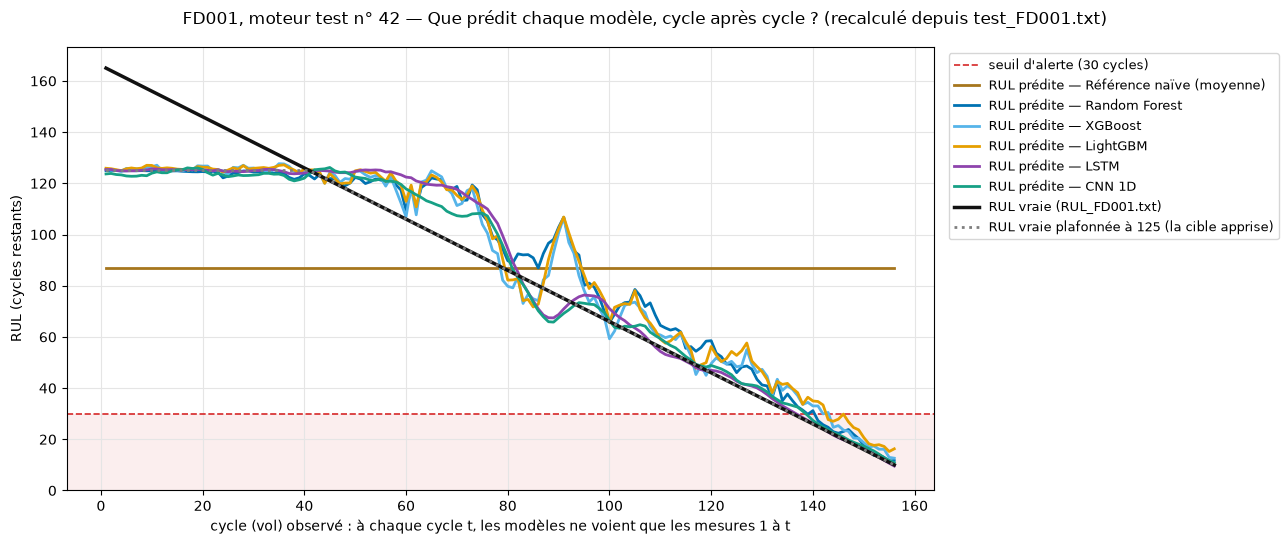

In [35]:
# --- (3) Figure : la RUL prédite cycle après cycle, recalculée depuis les données brutes, avec la vérité ---
figure = fr.figure_trajectoire_moteur(verification, montrer_verite=True)
plt.show()

**(4) Comparaison aux fichiers de la démo** : pour chaque modèle et chaque cycle, la RUL recalculée ci-dessus contre la RUL du fichier `sorties/predictions/<SOUS_JEU>__<modèle>.csv.gz` que lit Streamlit, et la vraie RUL des deux côtés. **Comment lire** : `identique` vaut vrai si l'écart maximal est ≤ 1e-4 cycle et si les vraies RUL sont les mêmes ; la cellule s'arrête sur une erreur sinon.

In [36]:
# --- (4) Comparaison aux fichiers de la démo (seule cellule de la section qui les ouvre) ---
detail, resume = es.comparer_aux_fichiers_demo(verification, tolerance=TOLERANCE_EGALITE)
display(resume.drop(columns=["cle"]).set_index("modele"))
assert resume["identique"].all(), "La prédiction recalculée diffère du fichier de la démo."
display(Markdown(f"**Ce qu'on lit (moteur {MOTEUR})** : pour les {len(resume)} modèles, la prédiction recalculée depuis "
                 f"`test_{SOUS_JEU}.txt` est celle des fichiers de la démo à chacun des {verification['nb_cycles']} cycles "
                 f"(écart maximal {resume['ecart_max'].max():.1e} cycle)."))

,nb_cycles_compares,ecart_max,identique,fichier
modele,,,,
Référence naïve (moyenne),156,0.000000e+00,True,sorties/predictions/FD001__reference_naive.csv.gz
Random Forest,156,1.421085e-14,True,sorties/predictions/FD001__random_forest.csv.gz
XGBoost,156,1.421085e-14,True,sorties/predictions/FD001__xgboost_phase3.csv.gz
LightGBM,156,1.421085e-14,True,sorties/predictions/FD001__lightgbm.csv.gz
LSTM,156,4.470348e-06,True,sorties/predictions/FD001__lstm.csv.gz
CNN 1D,156,1.490116e-05,True,sorties/predictions/FD001__cnn1d.csv.gz


**Ce qu'on lit (moteur 42)** : pour les 6 modèles, la prédiction recalculée depuis `test_FD001.txt` est celle des fichiers de la démo à chacun des 156 cycles (écart maximal 1.5e-05 cycle).

---

**Reproduire ce notebook** : depuis la racine du dépôt, `python scripts/generer_notebooks_resultats.py` régénère les 4 notebooks (`--sous-jeux FD002` pour un seul, `--entrainer` pour réentraîner les arbres et vérifier). Le script écrit le sous-jeu dans la cellule de paramètres de chaque `FD00X.ipynb` : rouvert à la main, un notebook généré recalcule bien son propre sous-jeu.

**Prérequis** (fichiers non versionnés, `sorties/` et `models/`), dans cet ordre :
1. `python scripts/preparer_demo.py` : prédictions des arbres, publication des réseaux du 04h (les 4 sous-jeux, à partir de `models/04h/`, rien n'est entraîné), modèles de l'inférence en direct ;
2. `LOKY_MAX_CPU_COUNT=4 python scripts/valider_arbres_finaux.py` : validation croisée des arbres avec leurs réglages finaux ;
3. `LOKY_MAX_CPU_COUNT=4 python scripts/valider_arbres_finaux.py --complements` : erreur d'entraînement des arbres et découpages neufs.

S'ils manquent, la section 1 s'arrête en donnant la commande (les compléments manquants sont seulement signalés).

In [37]:
# --- Durée totale d'exécution ---
print(f"Notebook {SOUS_JEU} exécuté en {time.perf_counter() - DEBUT_NOTEBOOK:.0f} s (ENTRAINER = {ENTRAINER}).")

Notebook FD001 exécuté en 12 s (ENTRAINER = False).
